# DS201 - Lab2: CNN



In [2]:
from pathlib import Path
import sys

candidates = [p for p in [Path.cwd(), Path.cwd().parent] if (p/'src/train.py').is_file()]
if not candidates and Path('/kaggle/input').exists():
    candidates = [p.parent.parent for p in Path('/kaggle/input').rglob('train.py') if p.parent.name == 'src']
if len(candidates) != 1:
    raise ValueError('Cần một workspace chứa src/train.py. Kiểm tra mã nguồn trong Input.')
WORKSPACE = candidates[0]
sys.path.insert(0, str(WORKSPACE))


## Thiết lập dữ liệu và thí nghiệm
Dữ liệu chỉ có train/test. Validation được tách từ train; dùng chung phép chia cho bảy cấu hình.

In [3]:
DATA_ROOT = "/kaggle/input/datasets/giahin/vinafood21/VinaFood21"
if DATA_ROOT is None:
    search = Path('/kaggle/input') if Path('/kaggle/input').exists() else WORKSPACE/'data'
    datasets = [p.parent for p in search.rglob('train')
                if p.is_dir() and (p.parent/'test').is_dir() and any(p.glob('*/*'))]
    if len(datasets) != 1:
        raise ValueError(f'Gán DATA_ROOT đến thư mục chứa train/test; tìm thấy: {datasets}')
    DATA_ROOT = datasets[0]
DATA_ROOT = Path(DATA_ROOT)


print('Dataset:', DATA_ROOT)


Dataset: /kaggle/input/datasets/giahin/vinafood21/VinaFood21


In [4]:
import torch
from src.train import run_experiment
from src.report import show_result, show_pair, results_frame
from src.artifacts import default_output_root

OUTPUT_ROOT = default_output_root()
print('Output folder:', OUTPUT_ROOT)
print('Device:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
results = {}

def run(name):
    result = run_experiment(WORKSPACE/'configs'/f'{name}.json', DATA_ROOT, output_root=OUTPUT_ROOT)
    results[name] = result
    show_result(result)


Output folder: /kaggle/working/outputs
Device: Tesla T4


## Bài 1: Xây dựng mô hình LeNet. Huấn luyện và đánh giá mô hình LeNet trên 4 độ đo precision, recall và F1-macro (sử dụng Adam làm optimizer).

**Kết quả:** số tham số và bảng layer; bốn độ đo test; F1 từng lớp; confusion matrix 21×21; so sánh macro-F1 của hai bản.


Train: 8035 | Validation: 2009 | Classes: 21
Seed: 42 | Validation split: split_from_train
Epoch 01/20 | train 2.7759/0.1506 | val 2.5923/0.2011 | macro-F1 0.1201
Epoch 02/20 | train 2.5511/0.2194 | val 2.4651/0.2424 | macro-F1 0.1670
Epoch 03/20 | train 2.4202/0.2551 | val 2.4405/0.2519 | macro-F1 0.1968
Epoch 04/20 | train 2.3132/0.2838 | val 2.3816/0.2713 | macro-F1 0.2104
Epoch 05/20 | train 2.2167/0.3103 | val 2.3539/0.2688 | macro-F1 0.2346
Epoch 06/20 | train 2.1187/0.3434 | val 2.3487/0.2942 | macro-F1 0.2518
Epoch 07/20 | train 2.0298/0.3729 | val 2.2852/0.2932 | macro-F1 0.2521
Epoch 08/20 | train 1.9432/0.3986 | val 2.3800/0.2812 | macro-F1 0.2663
Epoch 09/20 | train 1.8678/0.4197 | val 2.3440/0.3011 | macro-F1 0.2773
Epoch 10/20 | train 1.7693/0.4553 | val 2.3840/0.3086 | macro-F1 0.2761
Epoch 11/20 | train 1.7072/0.4665 | val 2.3849/0.2962 | macro-F1 0.2759
Epoch 12/20 | train 1.6005/0.4984 | val 2.3894/0.2982 | macro-F1 0.2850
Epoch 13/20 | train 1.5521/0.5120 | val 2.488

### LeNet · AvgPool

,Resize,Số tham số,Tham số được học,Best epoch,Giây/epoch
0,64×64,339421,339421,18,113.843408


**Bảng layer và tham số**

,layer,type,output_shape,parameters
0,c1,Conv2d,"(2, 6, 60, 60)",456
1,s2,AvgPool2d,"(2, 6, 30, 30)",0
2,c3,Conv2d,"(2, 16, 26, 26)",2416
3,s4,AvgPool2d,"(2, 16, 13, 13)",0
4,f5,Linear,"(2, 120)",324600
5,f6,Linear,"(2, 84)",10164
6,out,Linear,"(2, 21)",1785


**Bốn độ đo trên tập test**

,Accuracy,Precision macro,Recall macro,F1 macro
0,0.267435,0.259258,0.250336,0.247931


**Kết quả từng lớp (bao gồm F1)**

,precision,recall,f1-score,support
class,,,,
banh-can,0.166667,0.207469,0.184843,241.0
banh-hoi,0.275362,0.469522,0.347138,607.0
banh-mi-chao,0.270677,0.249135,0.259459,289.0
banh-tet,0.217252,0.186813,0.200886,364.0
banh-trang-tron,0.213115,0.084142,0.120650,309.0
banh-u,0.177083,0.096591,0.125000,176.0
banh-uot,0.214765,0.171429,0.190665,560.0
bap-nuong,0.070175,0.027972,0.040000,143.0
bo-kho,0.273885,0.254438,0.263804,338.0


**Confusion matrix 21×21**

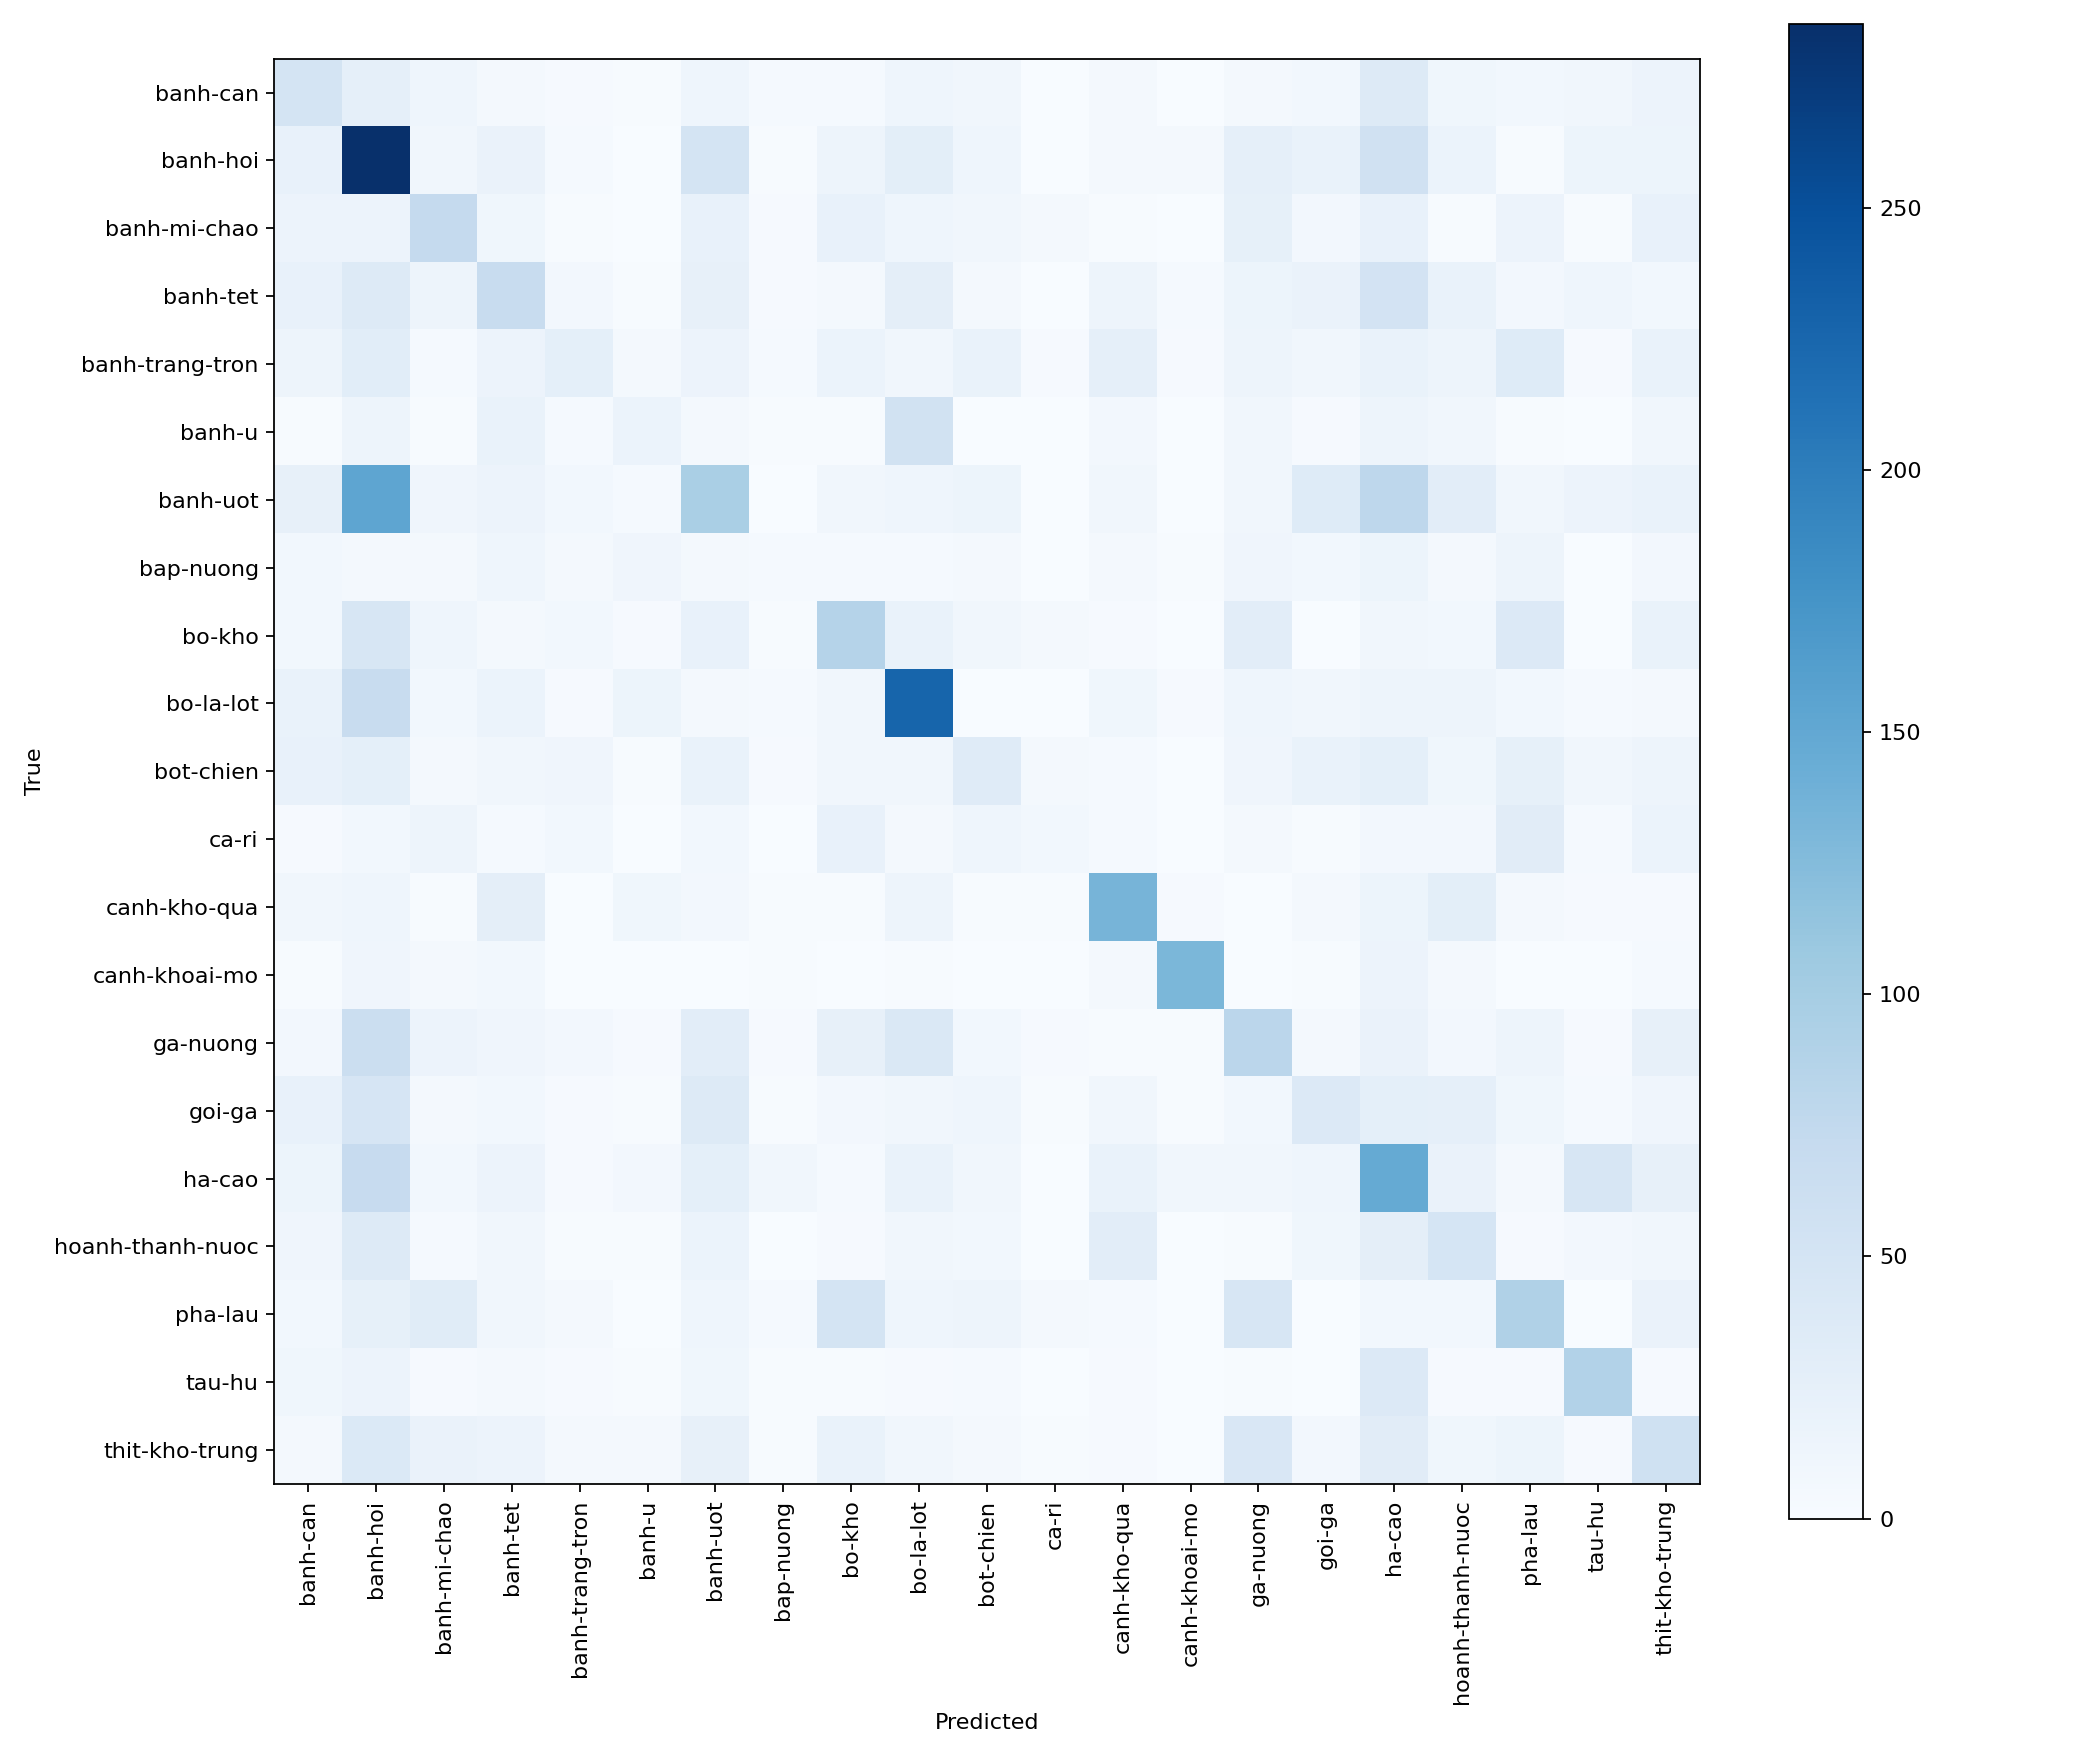

**Loss train và validation theo epoch**

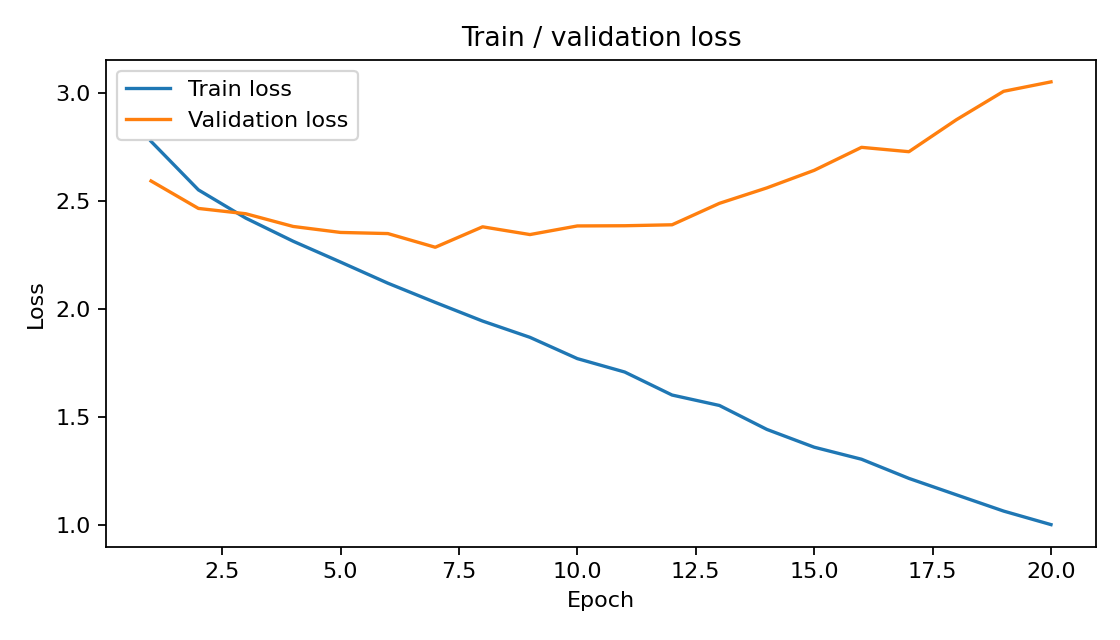

Train: 8035 | Validation: 2009 | Classes: 21
Seed: 42 | Validation split: split_from_train
Epoch 01/20 | train 2.7748/0.1533 | val 2.5817/0.2066 | macro-F1 0.1313
Epoch 02/20 | train 2.5263/0.2261 | val 2.4227/0.2578 | macro-F1 0.1939
Epoch 03/20 | train 2.3863/0.2704 | val 2.4119/0.2698 | macro-F1 0.2153
Epoch 04/20 | train 2.2646/0.3032 | val 2.3297/0.2892 | macro-F1 0.2419
Epoch 05/20 | train 2.1422/0.3421 | val 2.2969/0.2882 | macro-F1 0.2529
Epoch 06/20 | train 2.0195/0.3767 | val 2.2628/0.3141 | macro-F1 0.2734
Epoch 07/20 | train 1.9309/0.4035 | val 2.2070/0.3250 | macro-F1 0.2888
Epoch 08/20 | train 1.8341/0.4295 | val 2.2403/0.3136 | macro-F1 0.3011
Epoch 09/20 | train 1.7317/0.4629 | val 2.2664/0.3320 | macro-F1 0.3064
Epoch 10/20 | train 1.6453/0.4882 | val 2.2550/0.3385 | macro-F1 0.3072
Epoch 11/20 | train 1.5796/0.5080 | val 2.3552/0.3295 | macro-F1 0.3164
Epoch 12/20 | train 1.4702/0.5409 | val 2.3023/0.3425 | macro-F1 0.3245
Epoch 13/20 | train 1.4079/0.5541 | val 2.392

### LeNet · MaxPool

,Resize,Số tham số,Tham số được học,Best epoch,Giây/epoch
0,64×64,339421,339421,14,81.060346


**Bảng layer và tham số**

,layer,type,output_shape,parameters
0,c1,Conv2d,"(2, 6, 60, 60)",456
1,s2,MaxPool2d,"(2, 6, 30, 30)",0
2,c3,Conv2d,"(2, 16, 26, 26)",2416
3,s4,MaxPool2d,"(2, 16, 13, 13)",0
4,f5,Linear,"(2, 120)",324600
5,f6,Linear,"(2, 84)",10164
6,out,Linear,"(2, 21)",1785


**Bốn độ đo trên tập test**

,Accuracy,Precision macro,Recall macro,F1 macro
0,0.29557,0.294902,0.298695,0.287943


**Kết quả từng lớp (bao gồm F1)**

,precision,recall,f1-score,support
class,,,,
banh-can,0.184564,0.228216,0.204082,241.0
banh-hoi,0.409429,0.271829,0.326733,607.0
banh-mi-chao,0.226415,0.332180,0.269285,289.0
banh-tet,0.302158,0.230769,0.261682,364.0
banh-trang-tron,0.157303,0.090615,0.114990,309.0
banh-u,0.260563,0.210227,0.232704,176.0
banh-uot,0.274510,0.125000,0.171779,560.0
bap-nuong,0.139535,0.041958,0.064516,143.0
bo-kho,0.293769,0.292899,0.293333,338.0


**Confusion matrix 21×21**

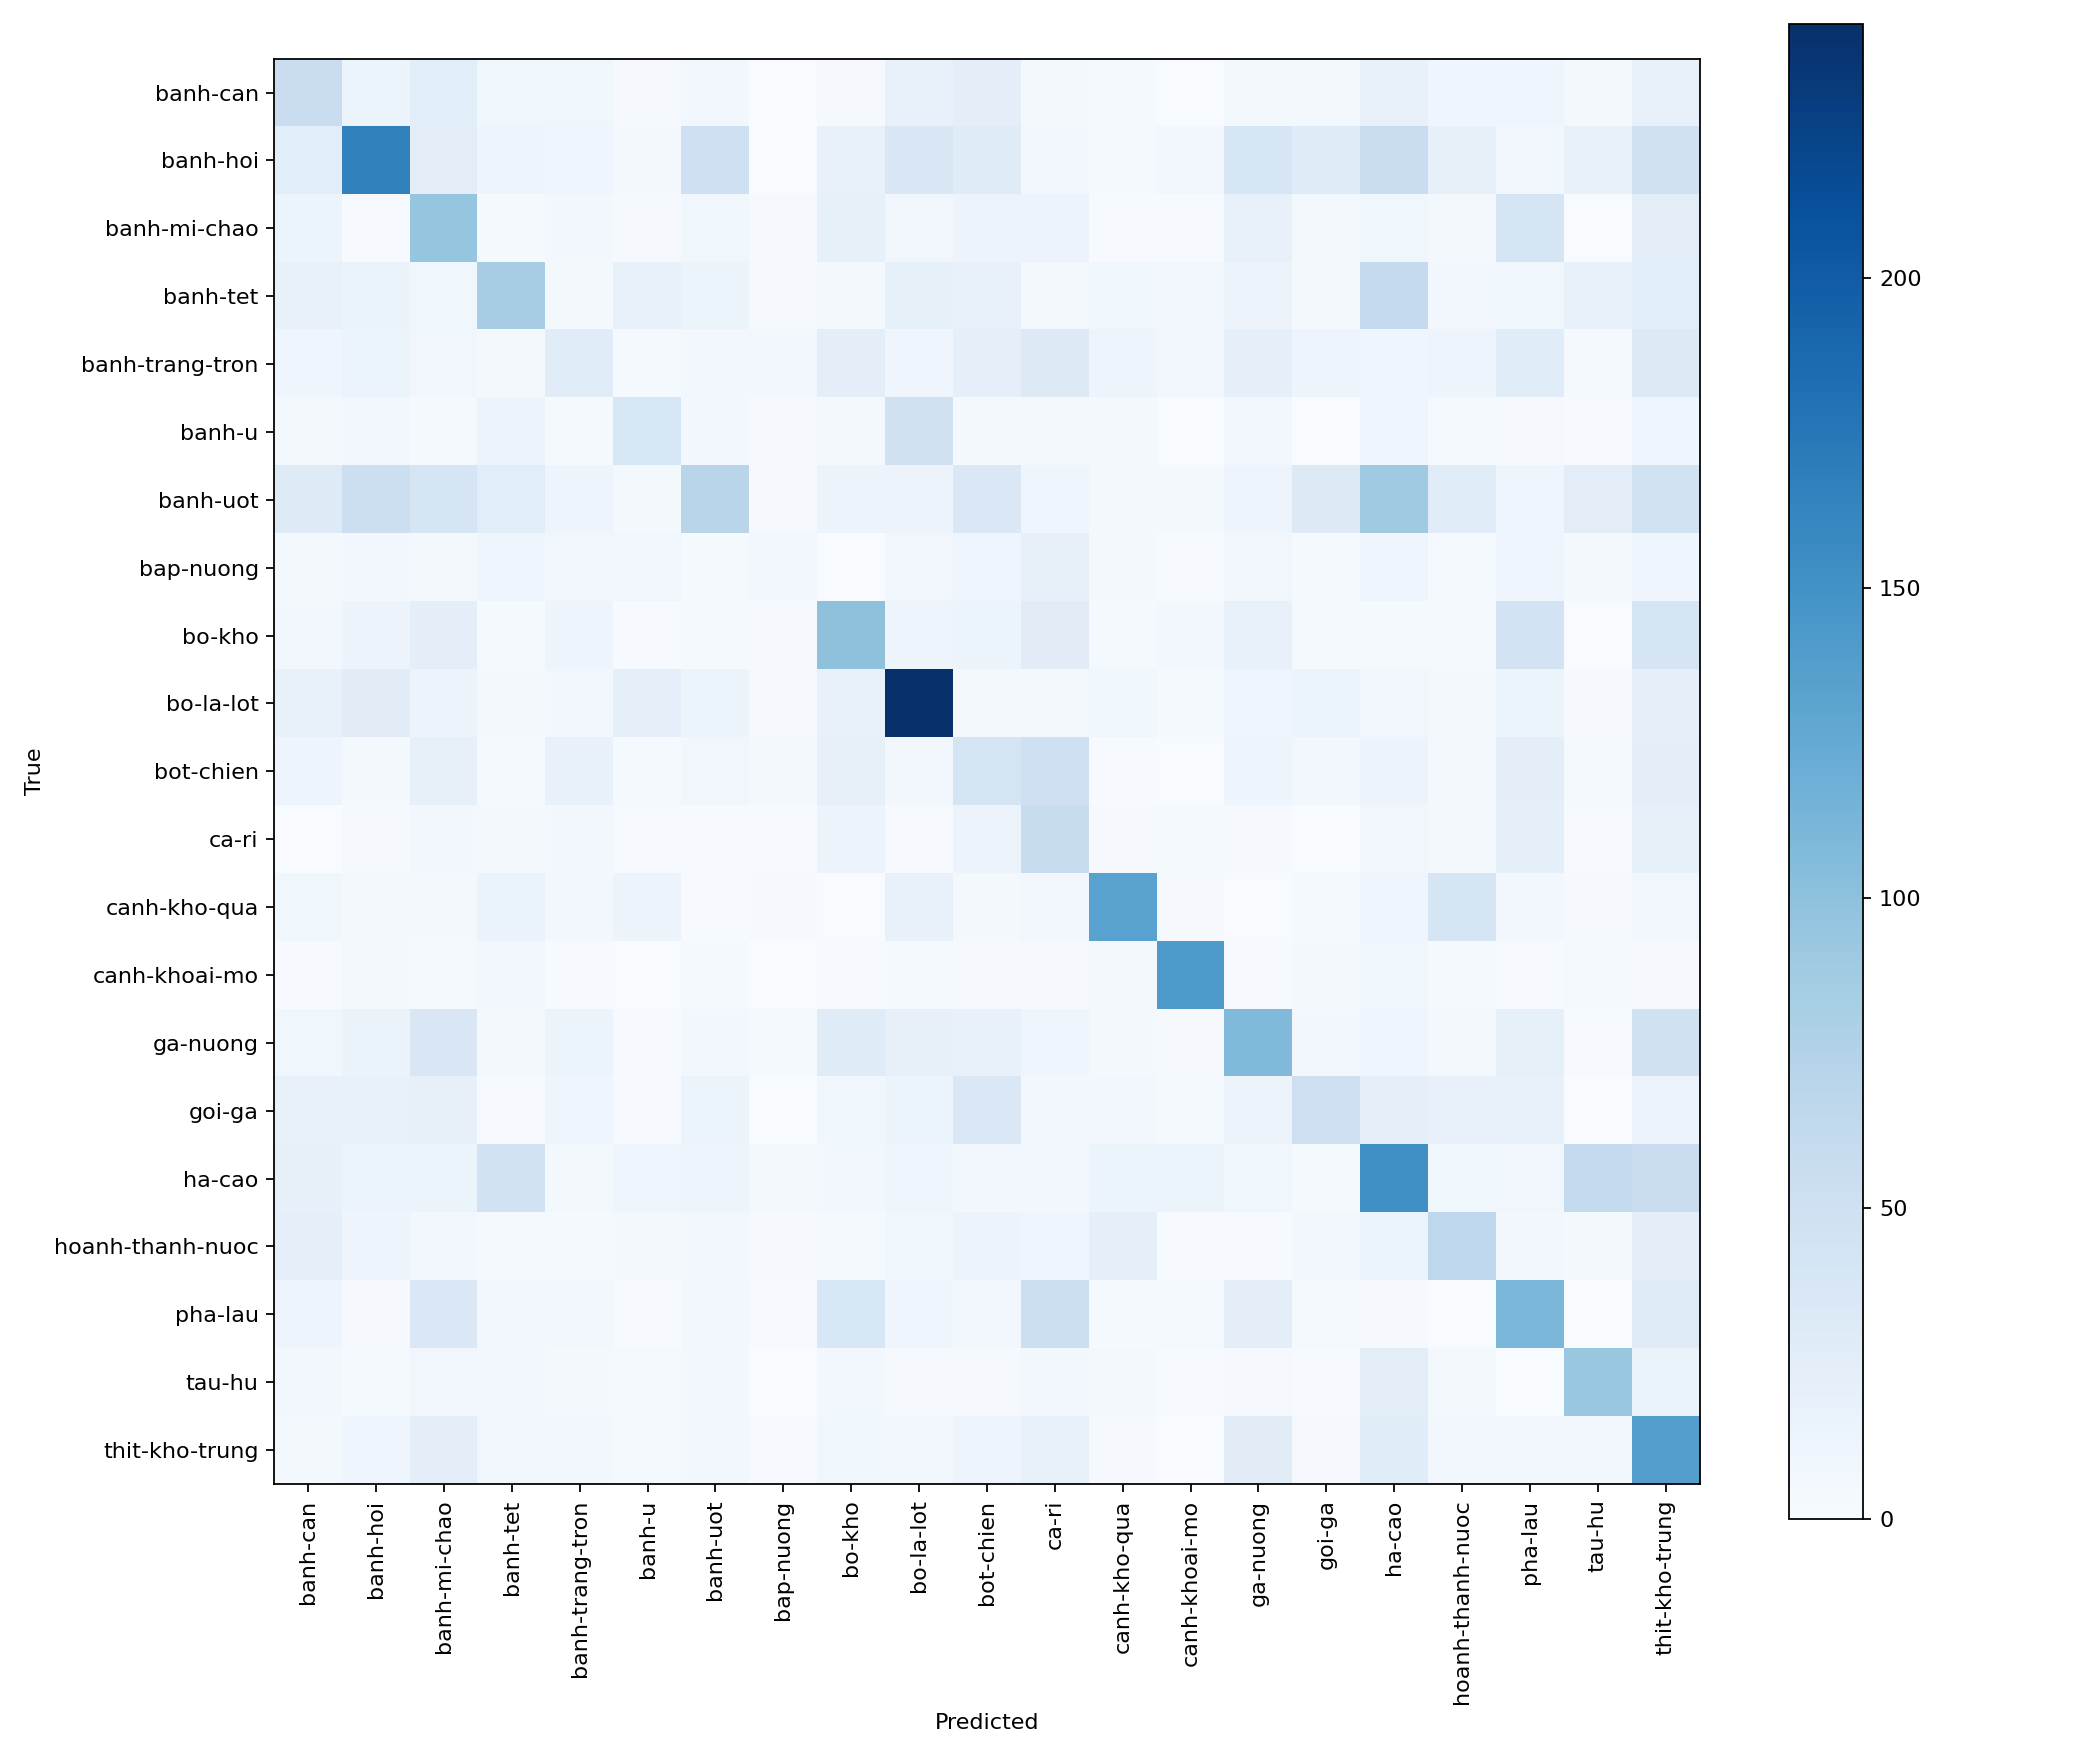

**Loss train và validation theo epoch**

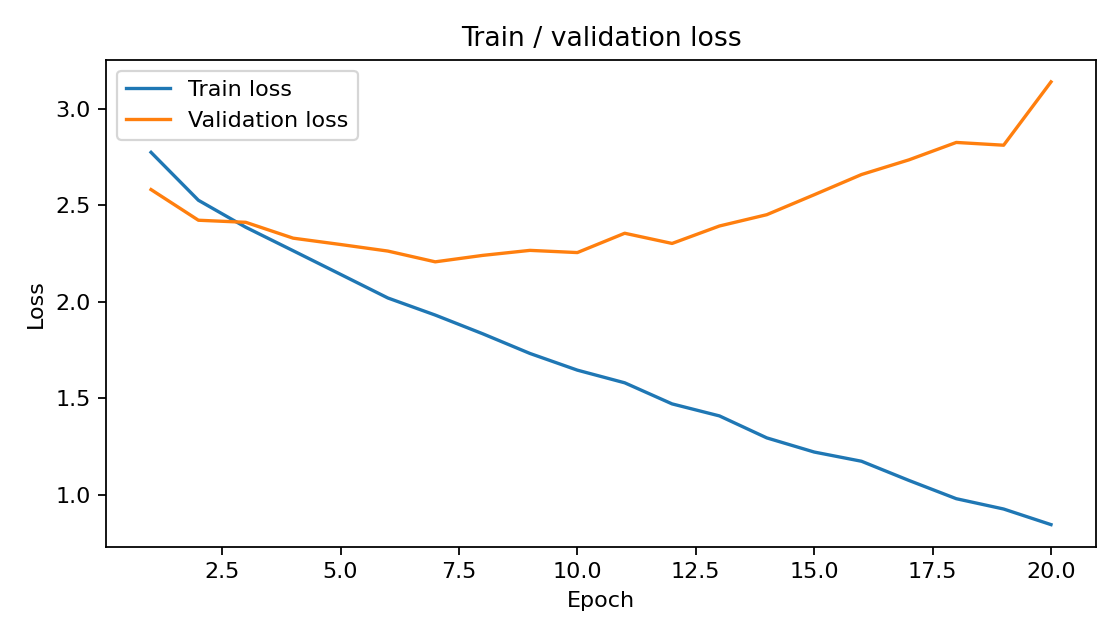

**So sánh AvgPool và MaxPool**

,Cấu hình,Tham số,Giây/epoch,Accuracy,Precision macro,Recall macro,F1 macro
0,LeNet · AvgPool,339421,113.843408,0.267435,0.259258,0.250336,0.247931
1,LeNet · MaxPool,339421,81.060346,0.295570,0.294902,0.298695,0.287943


Comparison: /kaggle/working/outputs/bai1/comparison.csv
Chênh lệch macro-F1 (LeNet · MaxPool − LeNet · AvgPool): +0.0400


In [5]:
run('lenet_avg')
run('lenet_max')
show_pair(results_frame(results), ['lenet_avg', 'lenet_max'], 'So sánh AvgPool và MaxPool',
          output_path=OUTPUT_ROOT/'bai1'/'comparison.csv')


MaxPool đạt macro-F1 28,79%, cao hơn AvgPool 24,79% khoảng 4,00 điểm phần trăm. Cả hai mô hình đều có dấu hiệu overfitting: validation loss tăng sau khoảng epoch 7 trong khi train loss tiếp tục giảm. Như vậy, thay đổi pooling giúp cải thiện kết quả nhưng chưa khắc phục được overfitting.

## Bài 2. Xây dựng mô hình GoogLeNet. Huấn luyện và đánh giá mô hình GoogLeNet trên 4 độ đo precision, recall và F1 (sử dụng Adam làm optimizer).

**Kết quả:** bốn độ đo test, F1 từng lớp và confusion matrix; channel mỗi block tính từ các nhánh và đối chiếu output; so sánh tham số, giây/epoch và macro-F1 với LeNet.


Train: 8035 | Validation: 2009 | Classes: 21
Seed: 42 | Validation split: split_from_train
Epoch 01/20 | train 2.8925/0.1165 | val 2.7661/0.1613 | macro-F1 0.0772
Epoch 02/20 | train 2.6173/0.1954 | val 2.4856/0.2220 | macro-F1 0.1511
Epoch 03/20 | train 2.4489/0.2352 | val 2.3853/0.2514 | macro-F1 0.1897
Epoch 04/20 | train 2.3382/0.2655 | val 2.3239/0.2728 | macro-F1 0.2281
Epoch 05/20 | train 2.2477/0.2973 | val 2.2893/0.2907 | macro-F1 0.2462
Epoch 06/20 | train 2.1715/0.3169 | val 2.1880/0.3041 | macro-F1 0.2727
Epoch 07/20 | train 2.1204/0.3318 | val 2.1322/0.3400 | macro-F1 0.3011
Epoch 08/20 | train 2.0529/0.3567 | val 2.0911/0.3459 | macro-F1 0.3291
Epoch 09/20 | train 1.9978/0.3759 | val 2.1156/0.3400 | macro-F1 0.3163
Epoch 10/20 | train 1.9519/0.3955 | val 1.9675/0.3838 | macro-F1 0.3405
Epoch 11/20 | train 1.9021/0.4052 | val 1.9732/0.3863 | macro-F1 0.3505
Epoch 12/20 | train 1.8698/0.4147 | val 1.9931/0.3883 | macro-F1 0.3516
Epoch 13/20 | train 1.8380/0.4355 | val 1.950

### GoogLeNet rút gọn

,Resize,Số tham số,Tham số được học,Best epoch,Giây/epoch
0,64×64,78221,78221,19,81.208677


**Channel từng Inception block: tính từ các nhánh và đối chiếu output**

,block,input_channels,branch_1x1,branch_3x3,branch_5x5,branch_pool,computed_channels,actual_channels,output_shape,parameters
0,1,3,16,24,8,8,56,56,"(2, 56, 64, 64)",4464
1,2,56,32,48,16,16,112,112,"(2, 112, 32, 32)",22104
2,3,112,64,64,32,32,192,192,"(2, 192, 16, 16)",47600


**Bốn độ đo trên tập test**

,Accuracy,Precision macro,Recall macro,F1 macro
0,0.390003,0.404059,0.387085,0.375729


**Kết quả từng lớp (bao gồm F1)**

,precision,recall,f1-score,support
class,,,,
banh-can,0.376238,0.157676,0.222222,241.0
banh-hoi,0.650113,0.474465,0.548571,607.0
banh-mi-chao,0.304348,0.460208,0.366391,289.0
banh-tet,0.578313,0.263736,0.362264,364.0
banh-trang-tron,0.311355,0.275081,0.292096,309.0
banh-u,0.274448,0.494318,0.352941,176.0
banh-uot,0.361290,0.400000,0.379661,560.0
bap-nuong,0.263736,0.167832,0.205128,143.0
bo-kho,0.389744,0.449704,0.417582,338.0


**Confusion matrix 21×21**

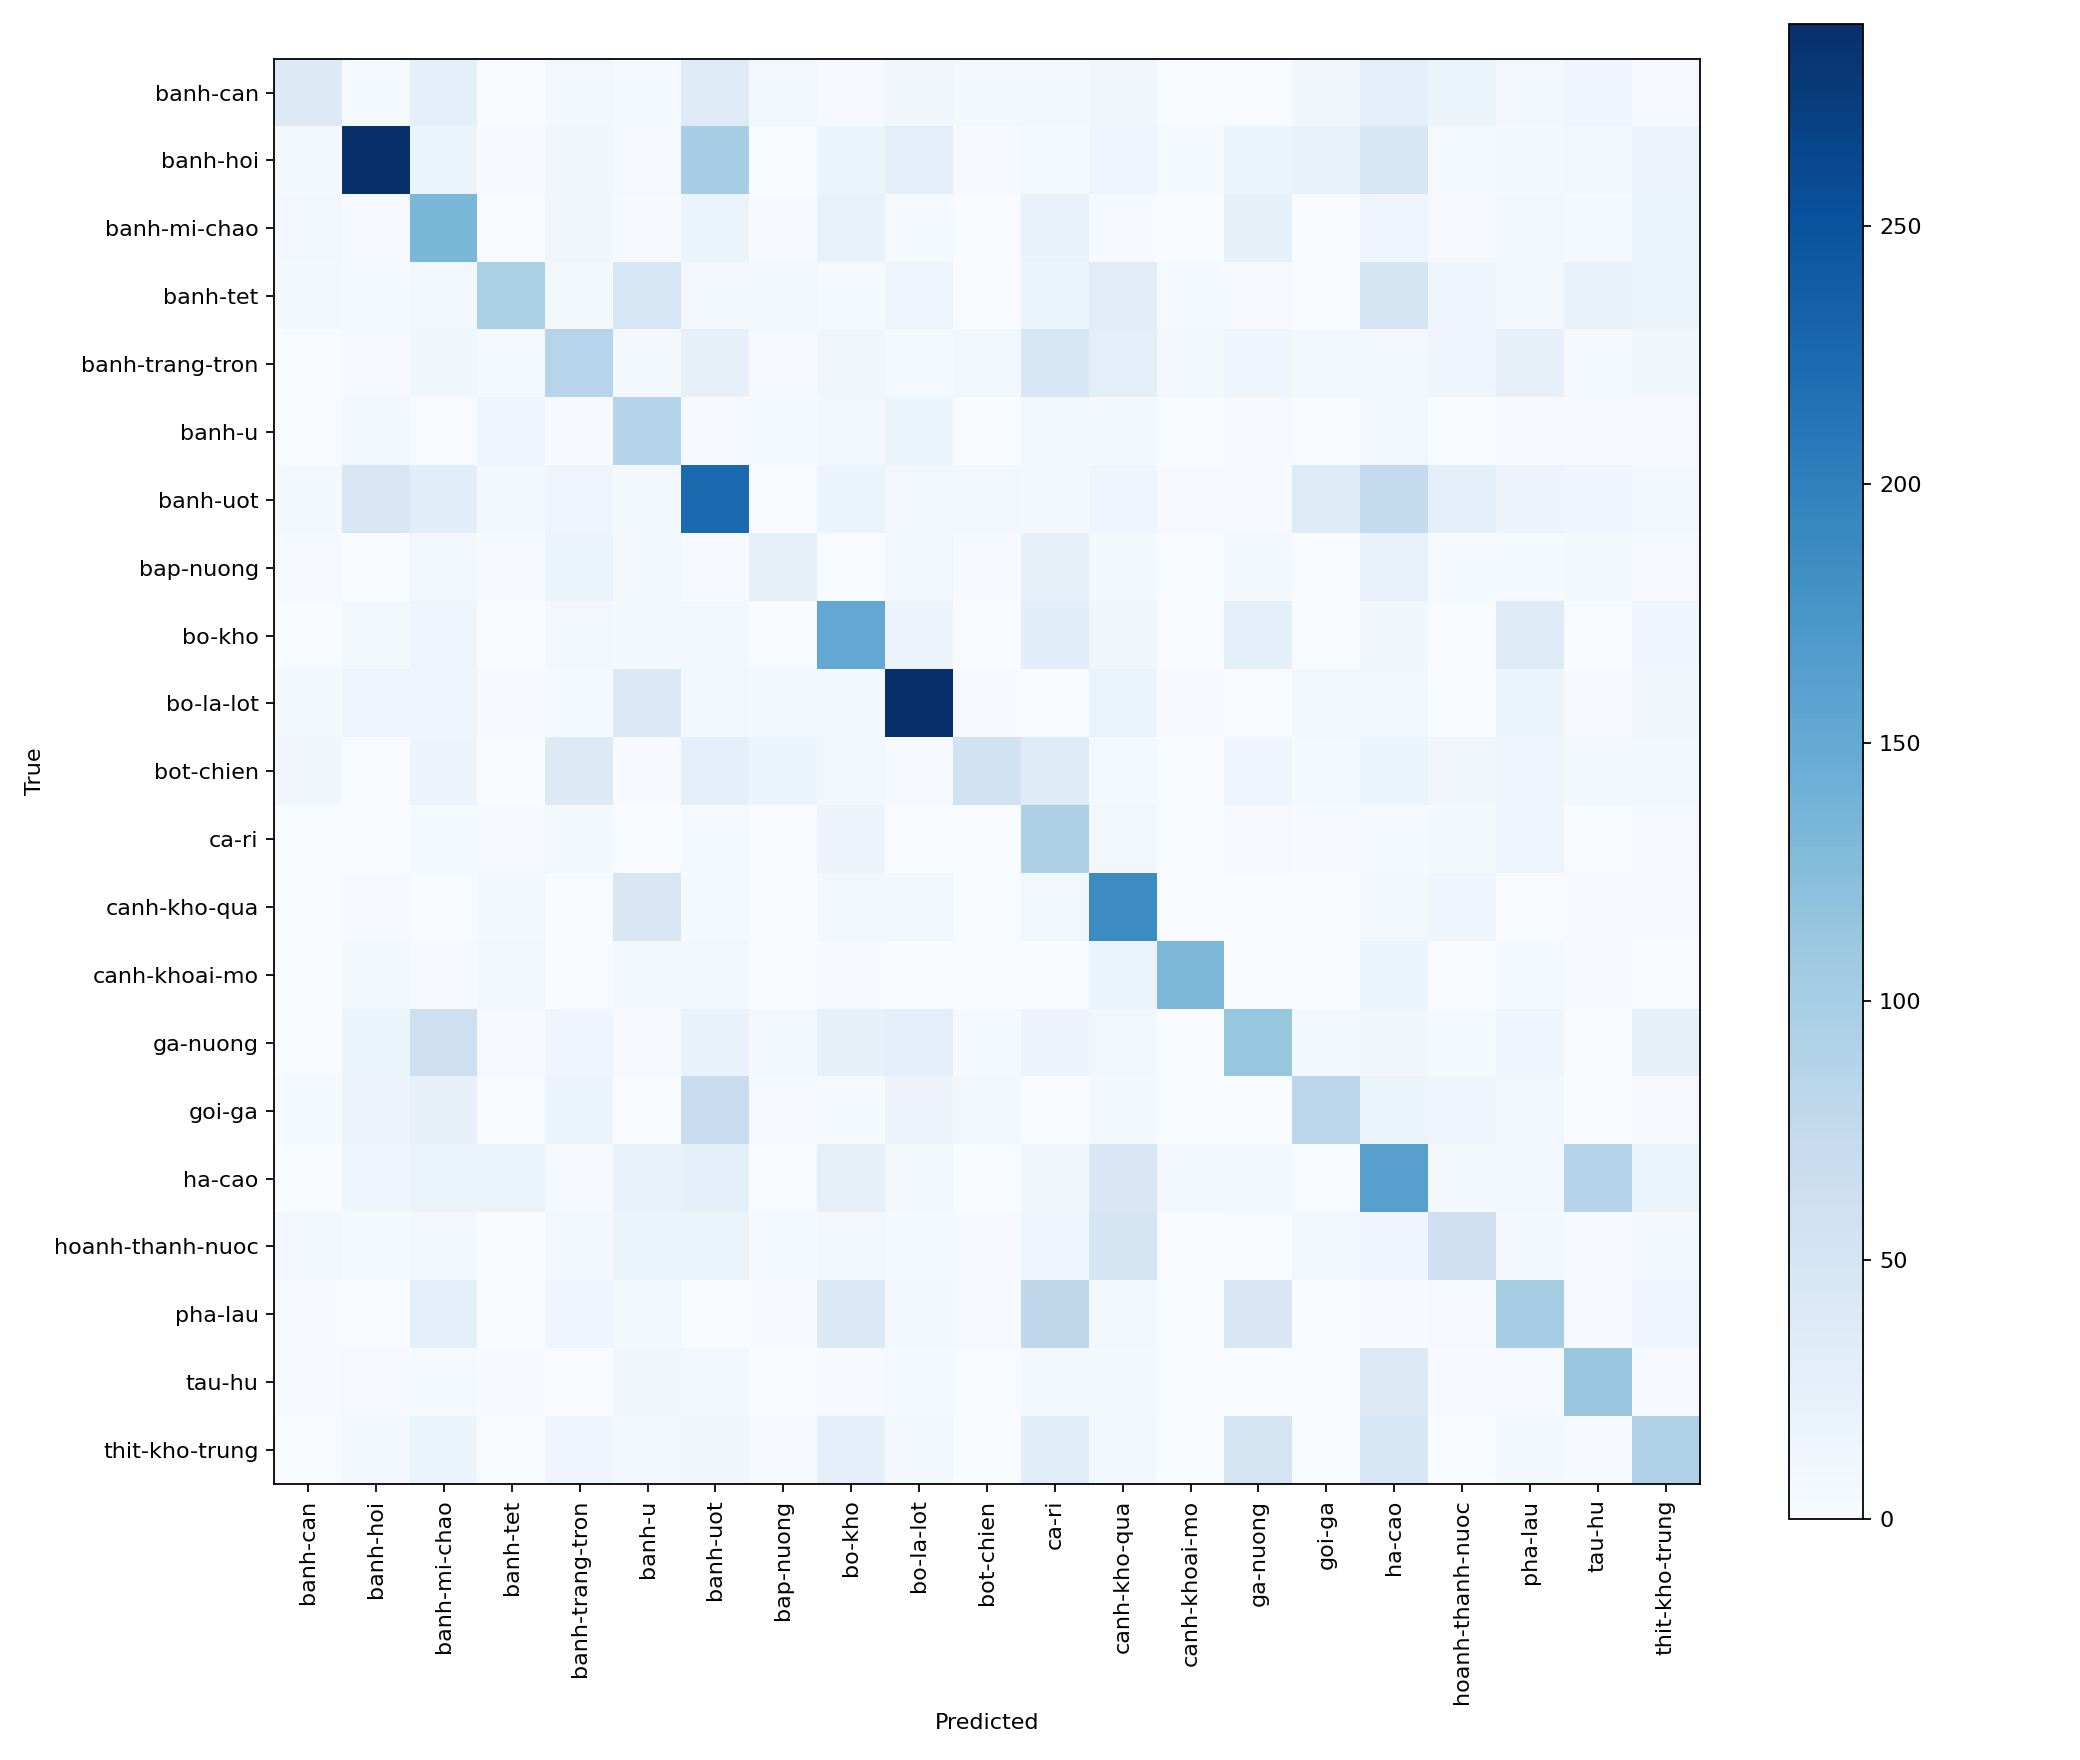

**Loss train và validation theo epoch**

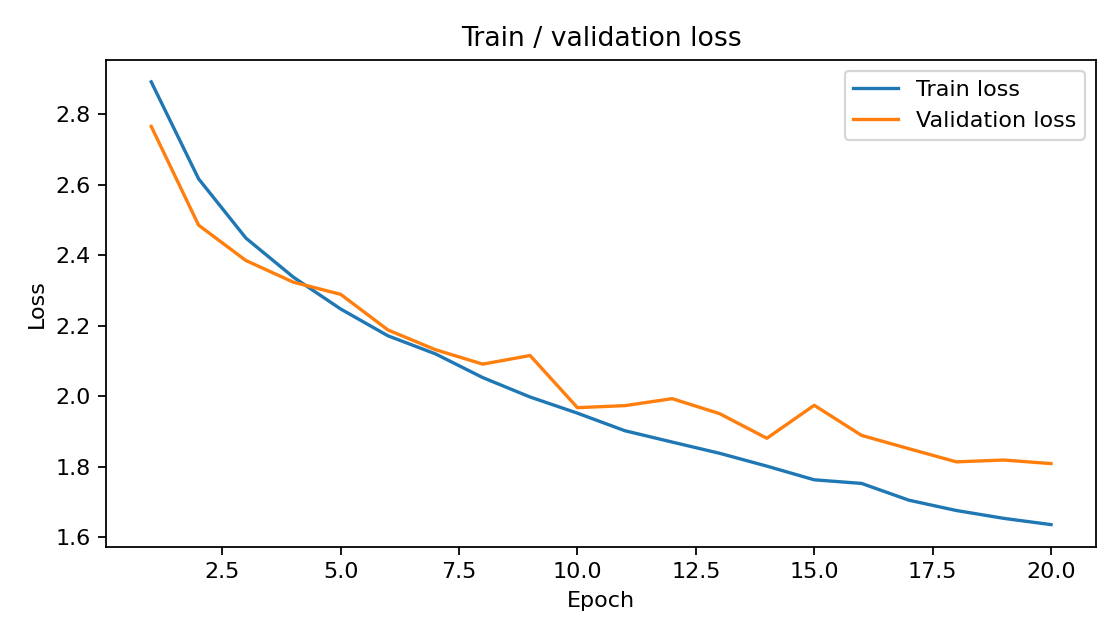

**So sánh GoogLeNet và LeNet**

,Cấu hình,Tham số,Giây/epoch,Accuracy,Precision macro,Recall macro,F1 macro
0,LeNet · AvgPool,339421,113.843408,0.267435,0.259258,0.250336,0.247931
1,LeNet · MaxPool,339421,81.060346,0.295570,0.294902,0.298695,0.287943
2,GoogLeNet rút gọn,78221,81.208677,0.390003,0.404059,0.387085,0.375729


Comparison: /kaggle/working/outputs/bai2/comparison.csv


In [6]:
run('googlenet_compact')
show_pair(results_frame(results), ['lenet_avg', 'lenet_max', 'googlenet_compact'], 'So sánh GoogLeNet và LeNet',
          output_path=OUTPUT_ROOT/'bai2'/'comparison.csv')


GoogLeNet rút gọn đạt macro-F1 37,57%, cao hơn hai phiên bản LeNet dù chỉ có 78.221 tham số, so với 339.421 của LeNet. Thời gian trung bình là 81,21 giây/epoch, gần bằng LeNet MaxPool (81,06 giây/epoch).

## Bài 3*: Xây dựng mô hình ResNet-18, đánh giá mô hình ResNet-18 trên bộ dữ liệu VinaFood21 sử dụng các độ đo precision, recall, và F1 (Sử dụng Adam làm optimizer).

**Kết quả:** bốn độ đo, F1 từng lớp, confusion matrix; loss train/validation theo epoch và chênh lệch macro-F1 giữa hai lần chạy.


Train: 8035 | Validation: 2009 | Classes: 21
Seed: 42 | Validation split: split_from_train
Epoch 01/20 | train 2.7345/0.1780 | val 2.7233/0.2190 | macro-F1 0.1288
Epoch 02/20 | train 2.5030/0.2322 | val 2.5109/0.2255 | macro-F1 0.1793
Epoch 03/20 | train 2.3590/0.2717 | val 2.3216/0.3051 | macro-F1 0.2447
Epoch 04/20 | train 2.2262/0.3180 | val 2.3006/0.3046 | macro-F1 0.2481
Epoch 05/20 | train 2.1260/0.3367 | val 2.3411/0.3016 | macro-F1 0.2952
Epoch 06/20 | train 2.0229/0.3676 | val 2.0928/0.3589 | macro-F1 0.3252
Epoch 07/20 | train 1.9247/0.3979 | val 2.0427/0.3912 | macro-F1 0.3453
Epoch 08/20 | train 1.8551/0.4185 | val 1.9441/0.4072 | macro-F1 0.3855
Epoch 09/20 | train 1.7735/0.4414 | val 1.9092/0.4126 | macro-F1 0.3765
Epoch 10/20 | train 1.6878/0.4686 | val 1.7722/0.4808 | macro-F1 0.4474
Epoch 11/20 | train 1.6368/0.4825 | val 1.9792/0.4102 | macro-F1 0.3865
Epoch 12/20 | train 1.5765/0.5074 | val 1.5802/0.5137 | macro-F1 0.4902
Epoch 13/20 | train 1.5086/0.5207 | val 1.750

### ResNet-18 · có augmentation

,Resize,Số tham số,Tham số được học,Best epoch,Giây/epoch
0,96×96,11187285,11187285,19,88.147139


**Bốn độ đo trên tập test**

,Accuracy,Precision macro,Recall macro,F1 macro
0,0.473661,0.49271,0.483473,0.471213


**Kết quả từng lớp (bao gồm F1)**

,precision,recall,f1-score,support
class,,,,
banh-can,0.392727,0.448133,0.418605,241.0
banh-hoi,0.646119,0.466227,0.541627,607.0
banh-mi-chao,0.387500,0.750865,0.511190,289.0
banh-tet,0.698113,0.406593,0.513889,364.0
banh-trang-tron,0.431034,0.242718,0.310559,309.0
banh-u,0.372694,0.573864,0.451902,176.0
banh-uot,0.485861,0.337500,0.398314,560.0
bap-nuong,0.571429,0.251748,0.349515,143.0
bo-kho,0.513889,0.437870,0.472843,338.0


**Confusion matrix 21×21**

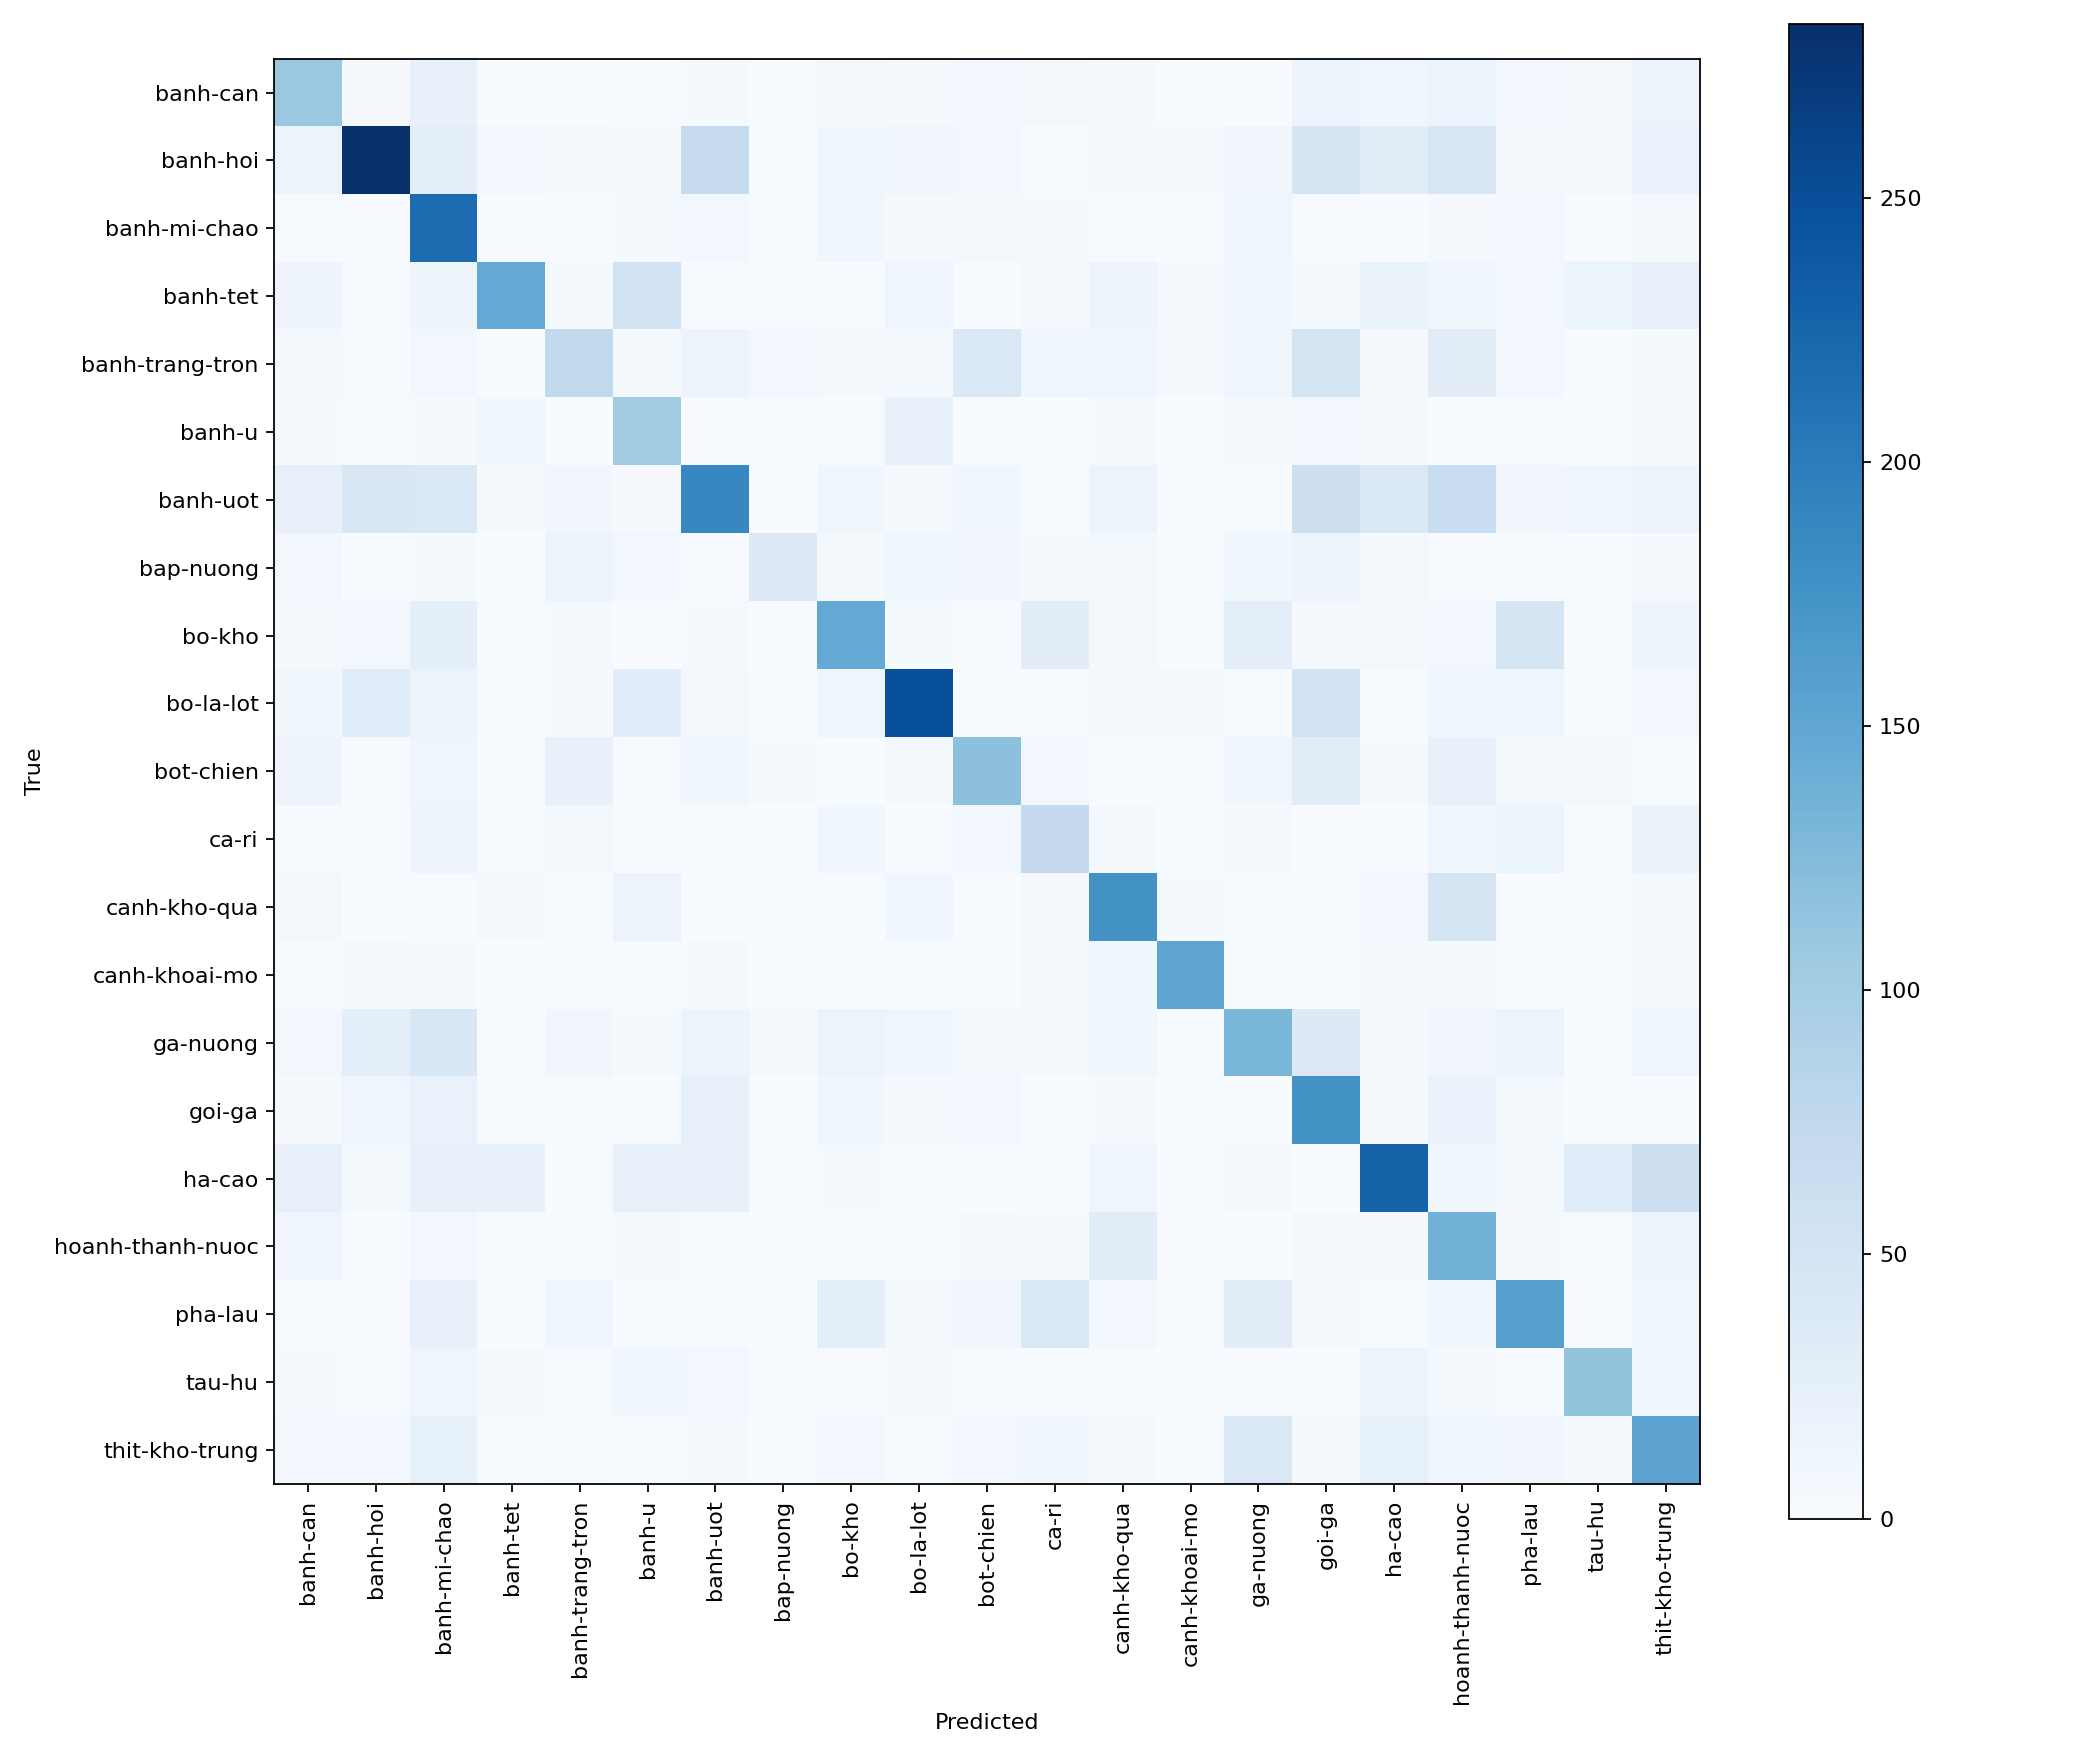

**Loss train và validation theo epoch**

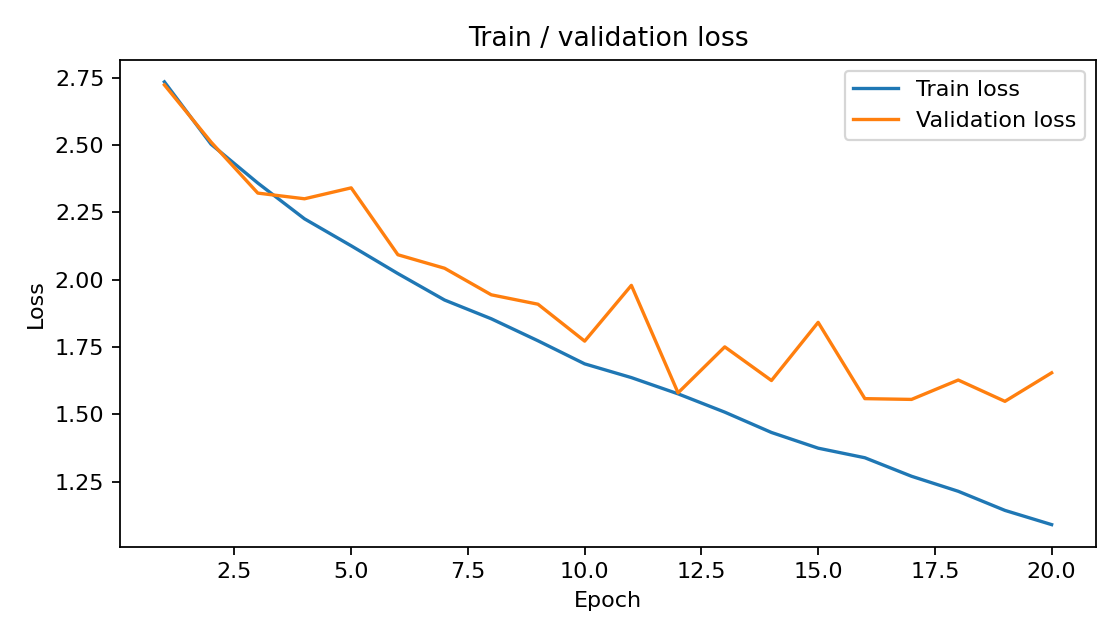

Train: 8035 | Validation: 2009 | Classes: 21
Seed: 42 | Validation split: split_from_train
Epoch 01/20 | train 2.6623/0.1993 | val 2.6977/0.2394 | macro-F1 0.1599
Epoch 02/20 | train 2.3971/0.2604 | val 2.3291/0.2787 | macro-F1 0.2300
Epoch 03/20 | train 2.2114/0.3145 | val 2.3429/0.2857 | macro-F1 0.2528
Epoch 04/20 | train 2.0194/0.3695 | val 2.1674/0.3315 | macro-F1 0.2774
Epoch 05/20 | train 1.8394/0.4198 | val 1.9705/0.3957 | macro-F1 0.3767
Epoch 06/20 | train 1.6556/0.4749 | val 2.1755/0.3718 | macro-F1 0.3386
Epoch 07/20 | train 1.4437/0.5445 | val 2.1138/0.3878 | macro-F1 0.3538
Epoch 08/20 | train 1.2169/0.6121 | val 2.0359/0.4156 | macro-F1 0.4011
Epoch 09/20 | train 0.9367/0.7007 | val 1.9916/0.4470 | macro-F1 0.4353
Epoch 10/20 | train 0.6306/0.7991 | val 2.4449/0.4251 | macro-F1 0.4019
Epoch 11/20 | train 0.4289/0.8645 | val 2.3732/0.4435 | macro-F1 0.4330
Epoch 12/20 | train 0.2617/0.9169 | val 2.6527/0.4574 | macro-F1 0.4520
Epoch 13/20 | train 0.2209/0.9291 | val 2.752

### ResNet-18 · không augmentation

,Resize,Số tham số,Tham số được học,Best epoch,Giây/epoch
0,96×96,11187285,11187285,15,83.8126


**Bốn độ đo trên tập test**

,Accuracy,Precision macro,Recall macro,F1 macro
0,0.401078,0.41472,0.383368,0.381404


**Kết quả từng lớp (bao gồm F1)**

,precision,recall,f1-score,support
class,,,,
banh-can,0.344660,0.294606,0.317673,241.0
banh-hoi,0.439655,0.504119,0.469685,607.0
banh-mi-chao,0.683544,0.186851,0.293478,289.0
banh-tet,0.537313,0.395604,0.455696,364.0
banh-trang-tron,0.280702,0.310680,0.294931,309.0
banh-u,0.297959,0.414773,0.346793,176.0
banh-uot,0.315068,0.328571,0.321678,560.0
bap-nuong,0.212500,0.118881,0.152466,143.0
bo-kho,0.313659,0.550296,0.399570,338.0


**Confusion matrix 21×21**

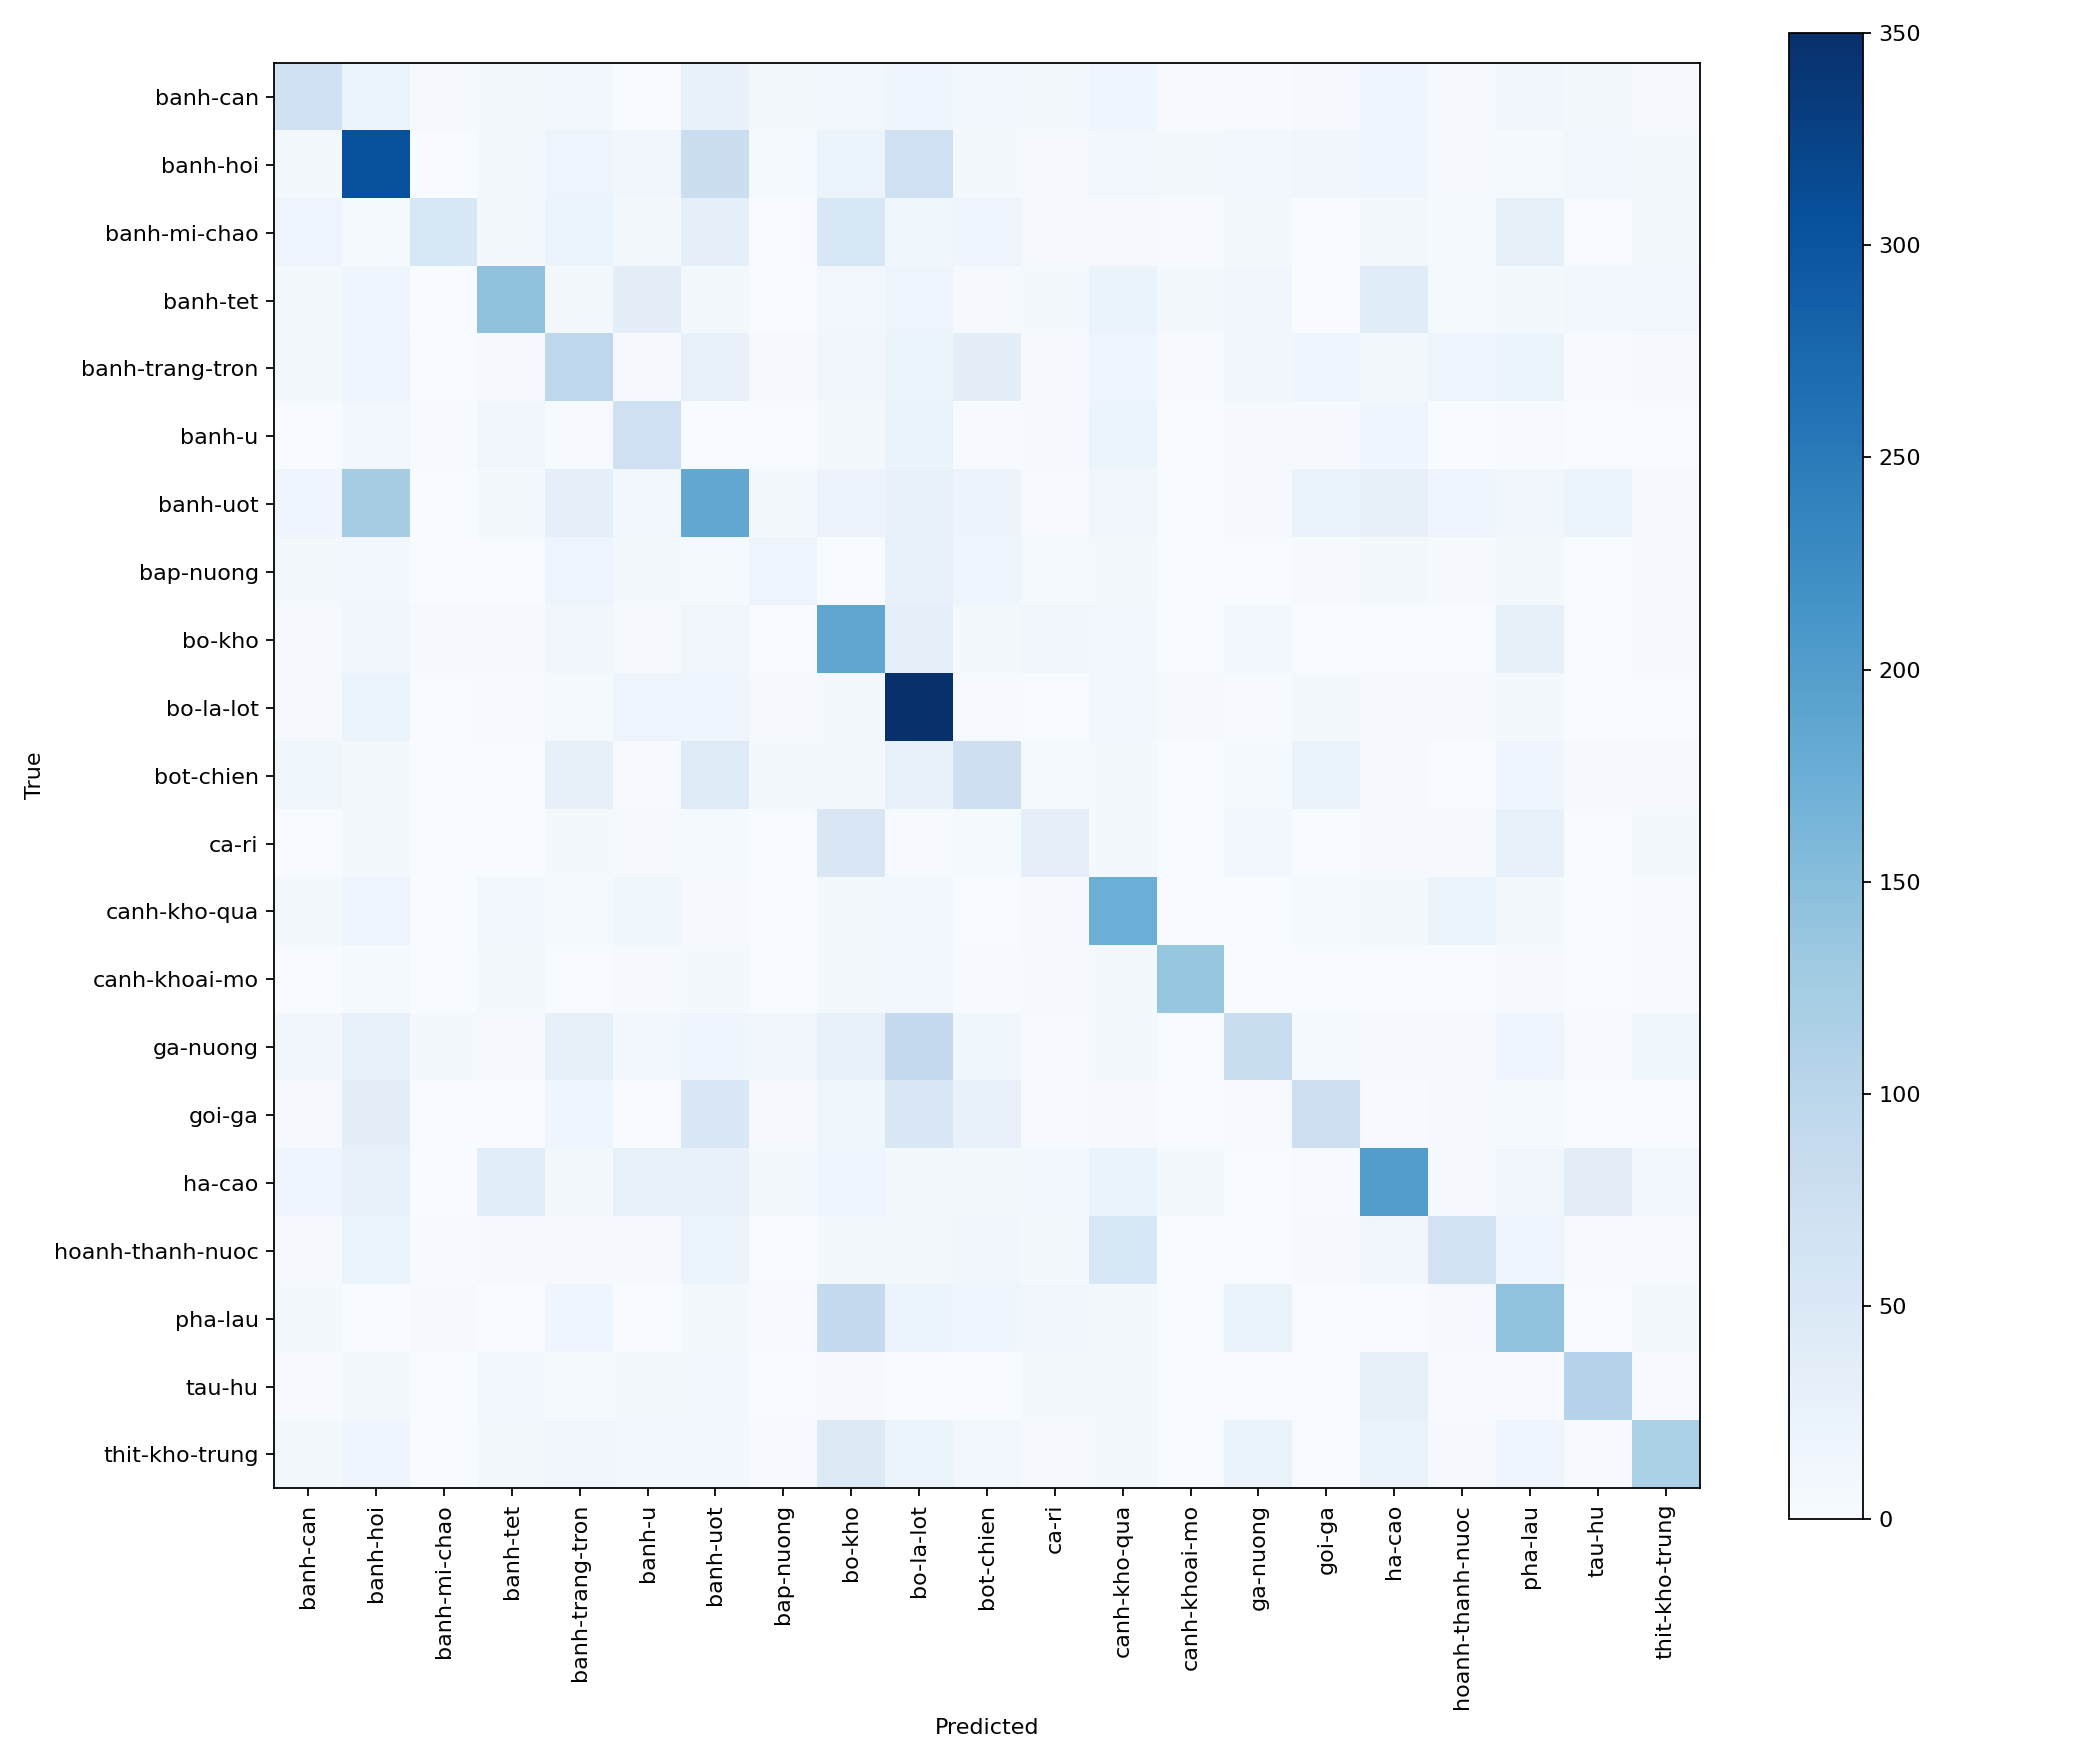

**Loss train và validation theo epoch**

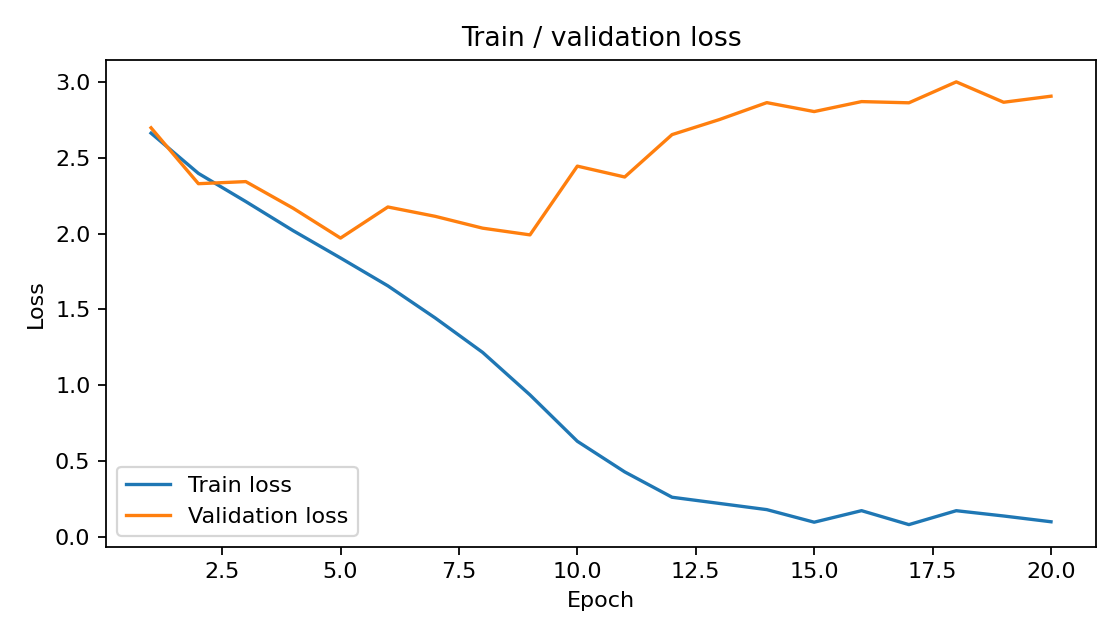

**Ảnh hưởng của augmentation**

,Cấu hình,Tham số,Giây/epoch,Accuracy,Precision macro,Recall macro,F1 macro
3,ResNet-18 · có augmentation,11187285,88.147139,0.473661,0.49271,0.483473,0.471213
4,ResNet-18 · không augmentation,11187285,83.812600,0.401078,0.41472,0.383368,0.381404


Comparison: /kaggle/working/outputs/bai3/comparison.csv
Chênh lệch macro-F1 (ResNet-18 · có augmentation − ResNet-18 · không augmentation): +0.0898


In [7]:
run('resnet18_aug')
run('resnet18_noaug')
show_pair(results_frame(results), ['resnet18_noaug', 'resnet18_aug'], 'Ảnh hưởng của augmentation',
          output_path=OUTPUT_ROOT/'bai3'/'comparison.csv')


ResNet18 không augmentation có hai đường loss tách rõ từ khoảng epoch 9–10: train loss giảm mạnh trong khi validation loss duy trì ở mức cao và tăng về cuối, cho thấy overfitting. Với augmentation, validation loss vẫn dao động nhưng nhìn chung giảm đến gần cuối quá trình. Macro-F1 tăng từ 38,14% lên 47,12%, tương ứng 8,98 điểm phần trăm, cho thấy augmentation giúp cải thiện khả năng tổng quát hóa.

## Bài 4*: Sử dụng pretrained ResNet50 từ HuggingFace để fine-tune trên bộ dữ liệu VinaFood21.

**Kết quả:** tổng tham số, số tham số được học, bốn độ đo, F1 từng lớp và confusion matrix cho cả hai chế độ; so sánh với ResNet-18 từ đầu.


Train: 8035 | Validation: 2009 | Classes: 21
Seed: 42 | Validation split: split_from_train


config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

...

**Bốn độ đo trên tập test**

,Accuracy,Precision macro,Recall macro,F1 macro
0,0.746932,0.759094,0.755449,0.752839


**Kết quả từng lớp (bao gồm F1)**

,precision,recall,f1-score,support
class,,,,
banh-can,0.746032,0.780083,0.762677,241.0
banh-hoi,0.760081,0.621087,0.683590,607.0
banh-mi-chao,0.768293,0.871972,0.816856,289.0
banh-tet,0.962687,0.708791,0.816456,364.0
banh-trang-tron,0.841085,0.702265,0.765432,309.0
banh-u,0.786096,0.835227,0.809917,176.0
banh-uot,0.577444,0.685714,0.626939,560.0
bap-nuong,0.952055,0.972028,0.961938,143.0
bo-kho,0.612903,0.730769,0.666667,338.0


**Confusion matrix 21×21**

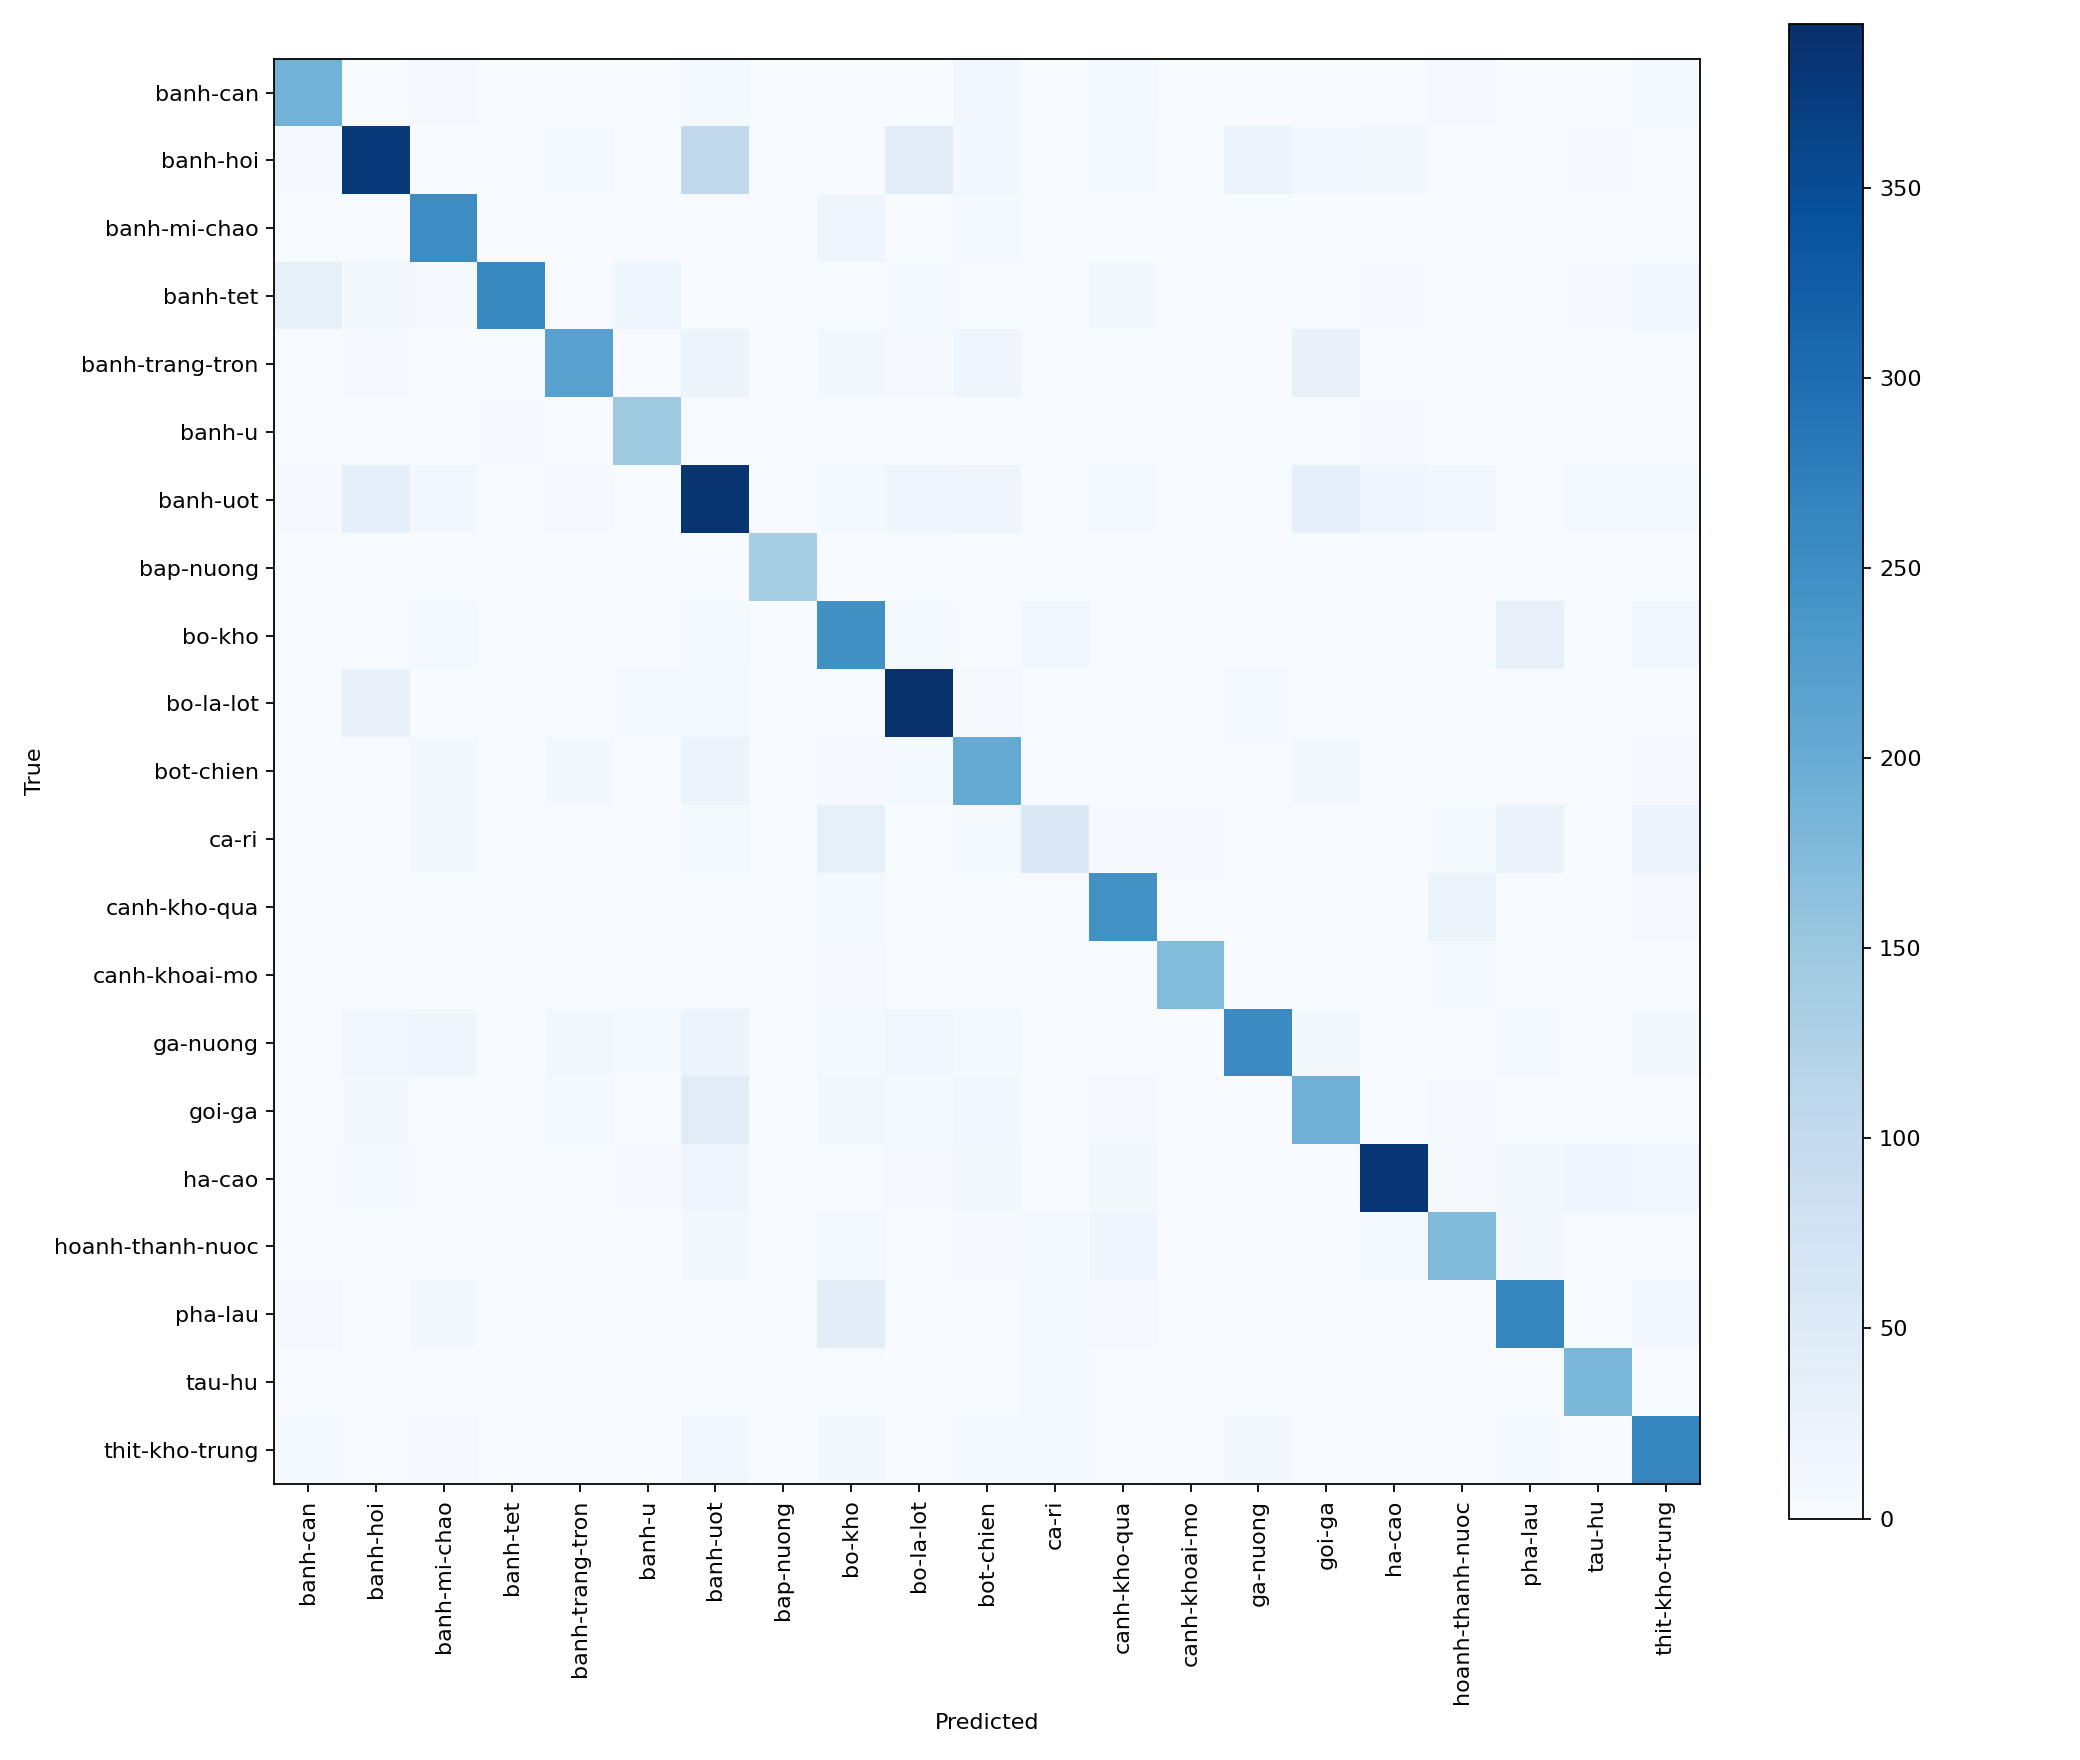

**Loss train và validation theo epoch**

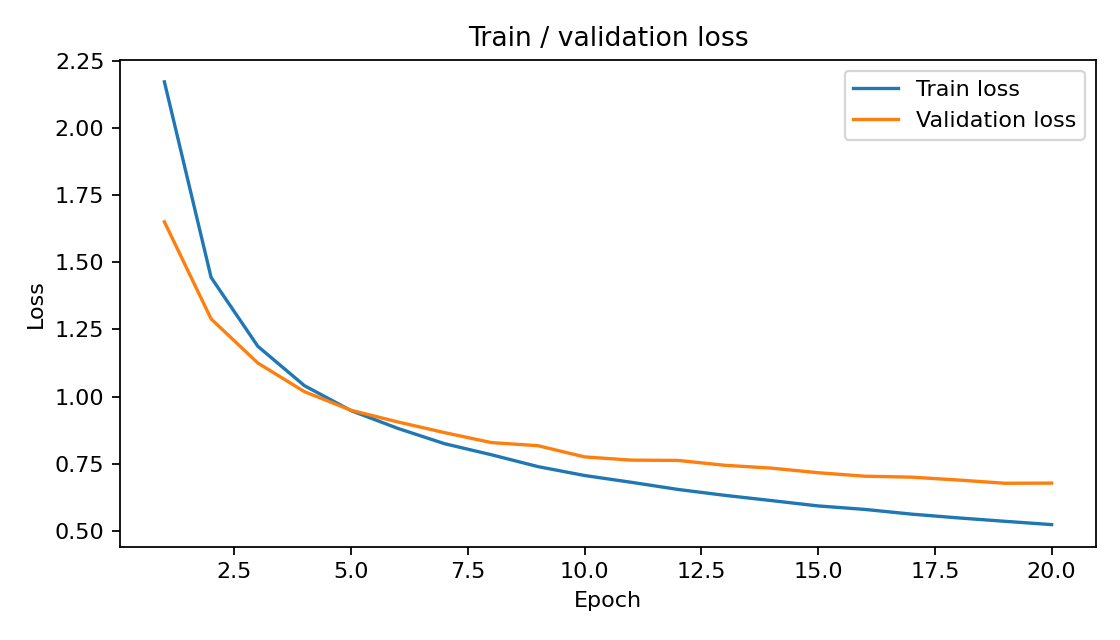

Train: 8035 | Validation: 2009 | Classes: 21
Seed: 42 | Validation split: split_from_train


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Epoch 01/20 | train 2.7762/0.1771 | val 2.3721/0.4077 | macro-F1 0.2805
Epoch 02/20 | train 1.7845/0.5322 | val 1.2134/0.6695 | macro-F1 0.6489
Epoch 03/20 | train 1.0579/0.6992 | val 0.8048/0.7646 | macro-F1 0.7495
Epoch 04/20 | train 0.7626/0.7742 | val 0.5963/0.8163 | macro-F1 0.8037
Epoch 05/20 | train 0.5943/0.8194 | val 0.5231/0.8387 | macro-F1 0.8286
Epoch 06/20 | train 0.4916/0.8462 | val 0.4746/0.8507 | macro-F1 0.8434
Epoch 07/20 | train 0.4128/0.8747 | val 0.4331/0.8606 | macro-F1 0.8561
Epoch 08/20 | train 0.3536/0.8917 | val 0.4091/0.8691 | macro-F1 0.8674
Epoch 09/20 | train 0.2964/0.9103 | val 0.3915/0.8681 | macro-F1 0.8651
Epoch 10/20 | train 0.2623/0.9190 | val 0.3881/0.8776 | macro-F1 0.8729
Epoch 11/20 | train 0.2336/0.9284 | val 0.3950/0.8731 | macro-F1 0.8701
Epoch 12/20 | train 0.2012/0.9381 | val 0.3790/0.8835 | macro-F1 0.8813
Epoch 13/20 | train 0.1710/0.9493 | val 0.3705/0.8820 | macro-F1 0.8786
Epoch 14/20 | train 0.1531/0.9569 | val 0.3706/0.8785 | macro-F1

### ResNet50 · fine-tuning

,Resize,Số tham số,Tham số được học,Best epoch,Giây/epoch
0,224×224,23551061,23551061,17,115.291088


**Bốn độ đo trên tập test**

,Accuracy,Precision macro,Recall macro,F1 macro
0,0.851092,0.850415,0.85598,0.851041


**Kết quả từng lớp (bao gồm F1)**

,precision,recall,f1-score,support
class,,,,
banh-can,0.842308,0.908714,0.874251,241.0
banh-hoi,0.880068,0.858320,0.869058,607.0
banh-mi-chao,0.939502,0.913495,0.926316,289.0
banh-tet,0.976351,0.793956,0.875758,364.0
banh-trang-tron,0.931408,0.834951,0.880546,309.0
banh-u,0.819095,0.926136,0.869333,176.0
banh-uot,0.872117,0.742857,0.802314,560.0
bap-nuong,0.927632,0.986014,0.955932,143.0
bo-kho,0.751366,0.813609,0.781250,338.0


**Confusion matrix 21×21**

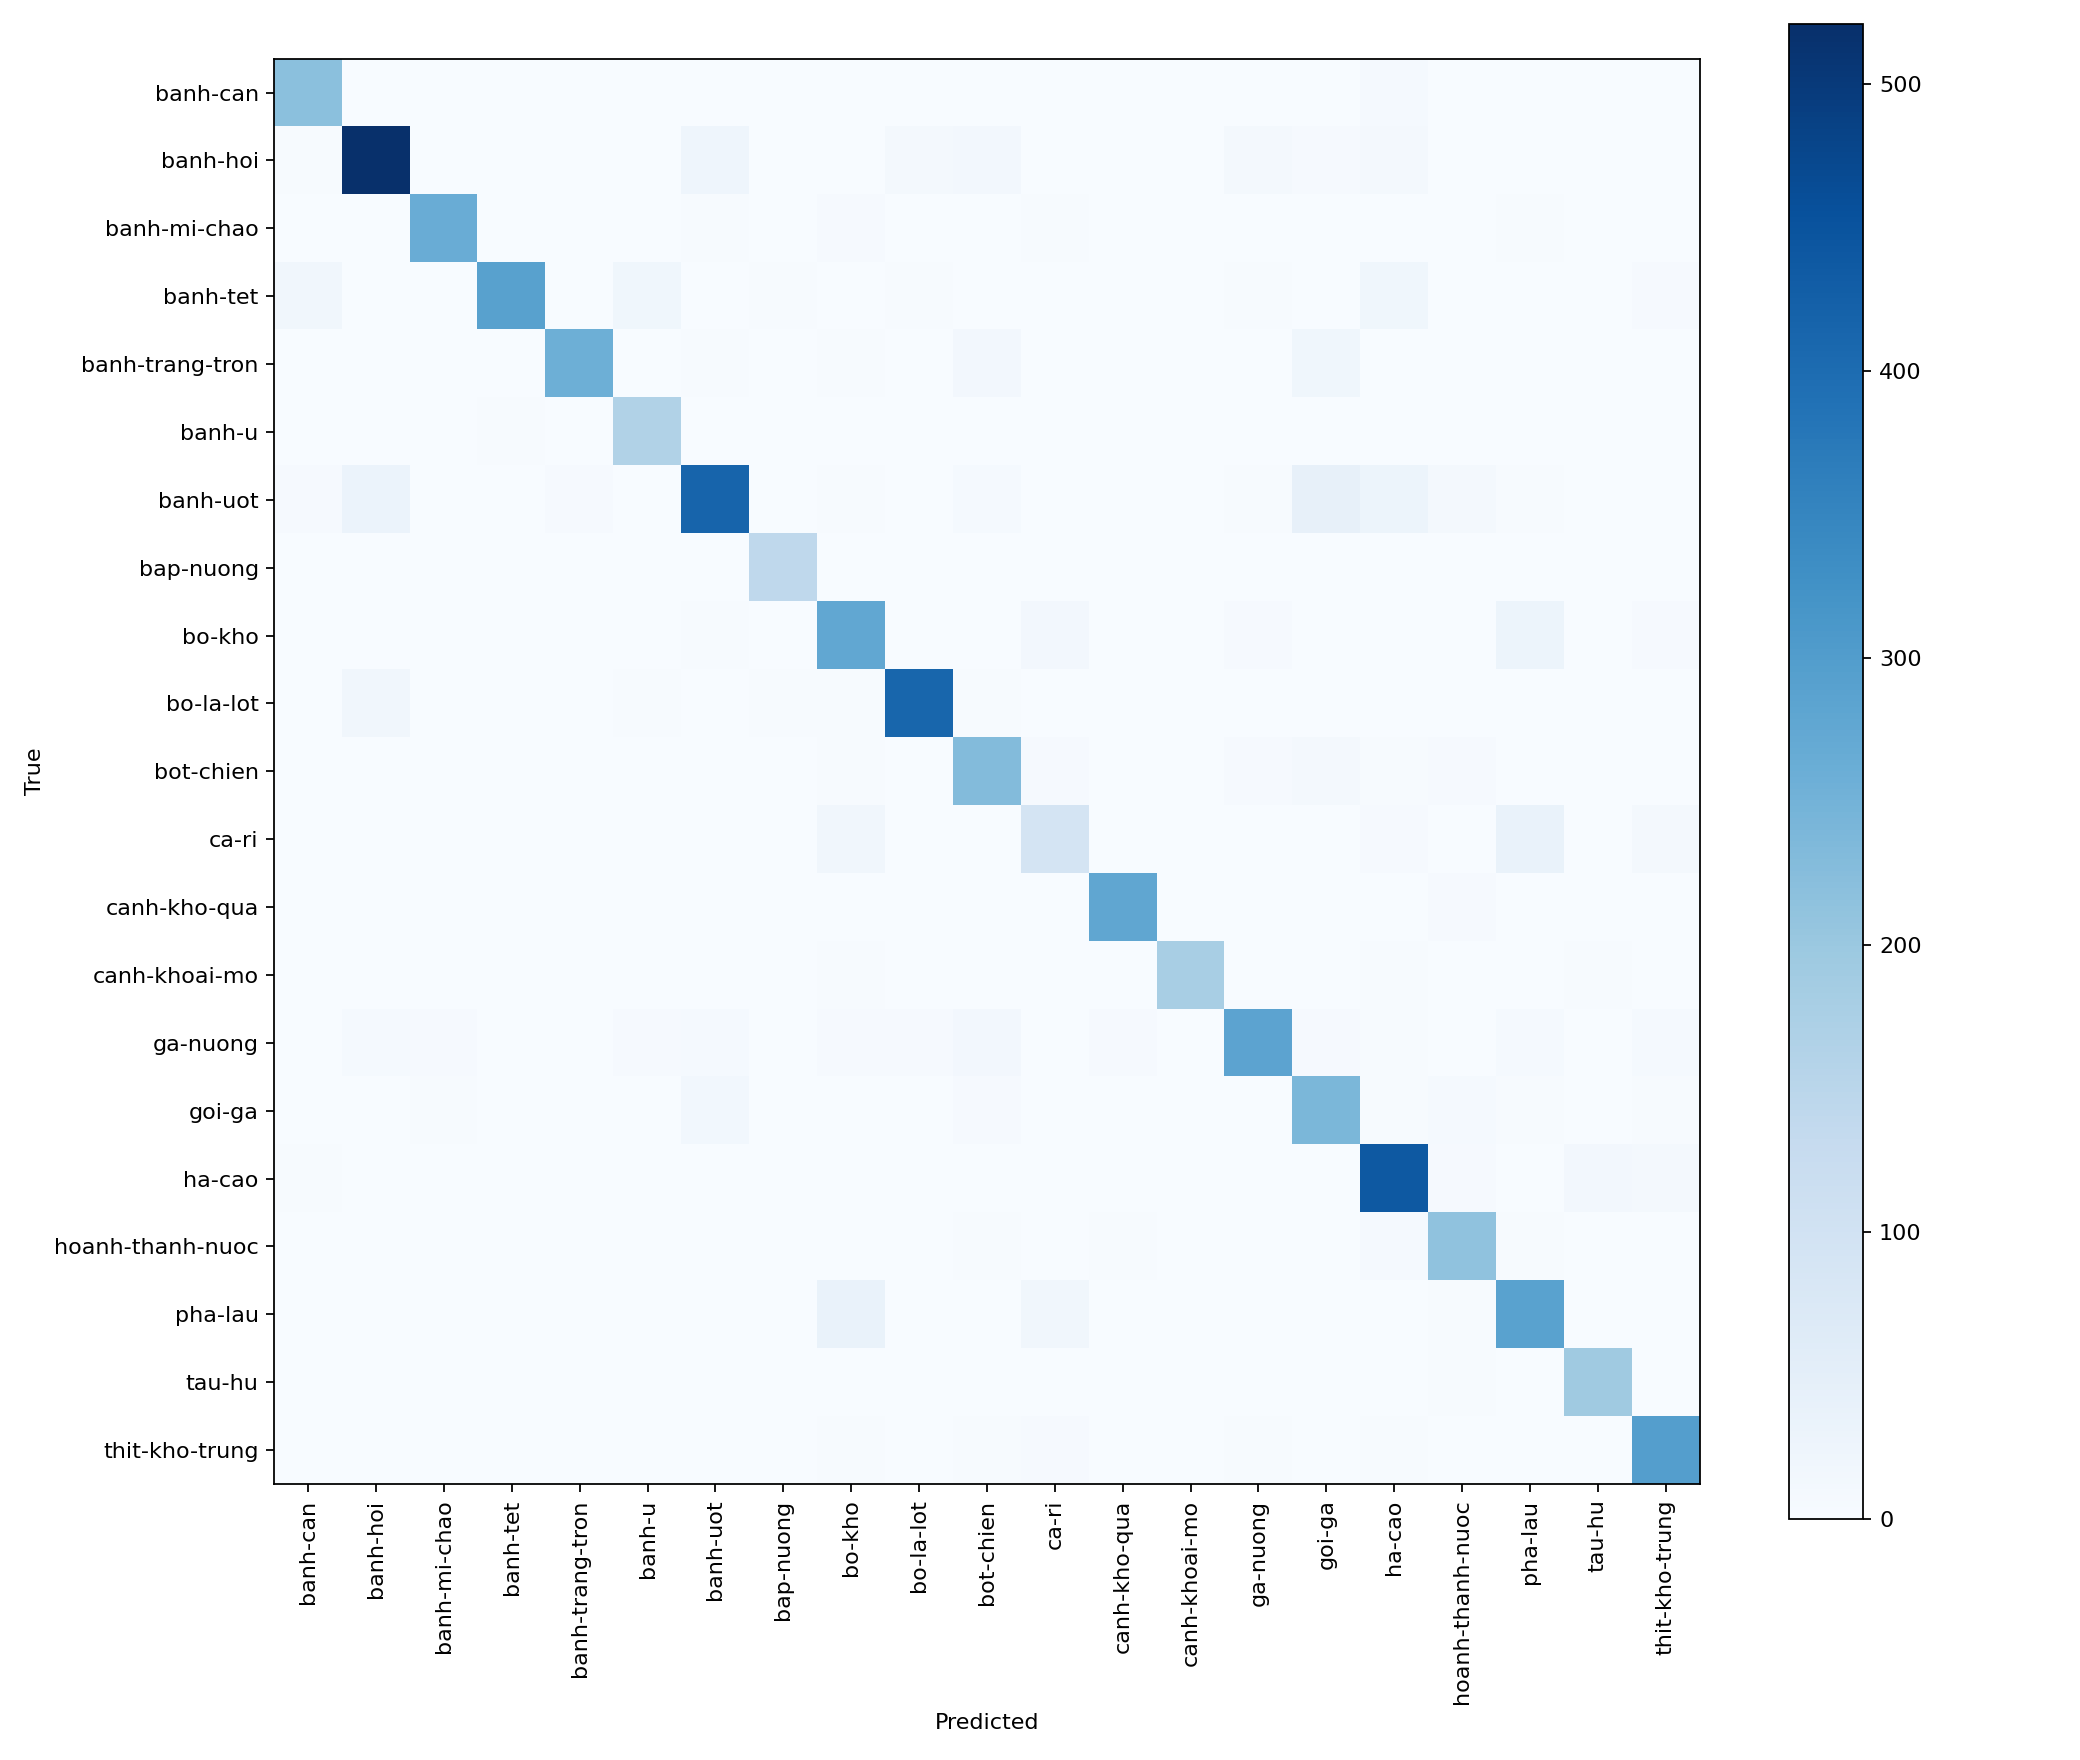

**Loss train và validation theo epoch**

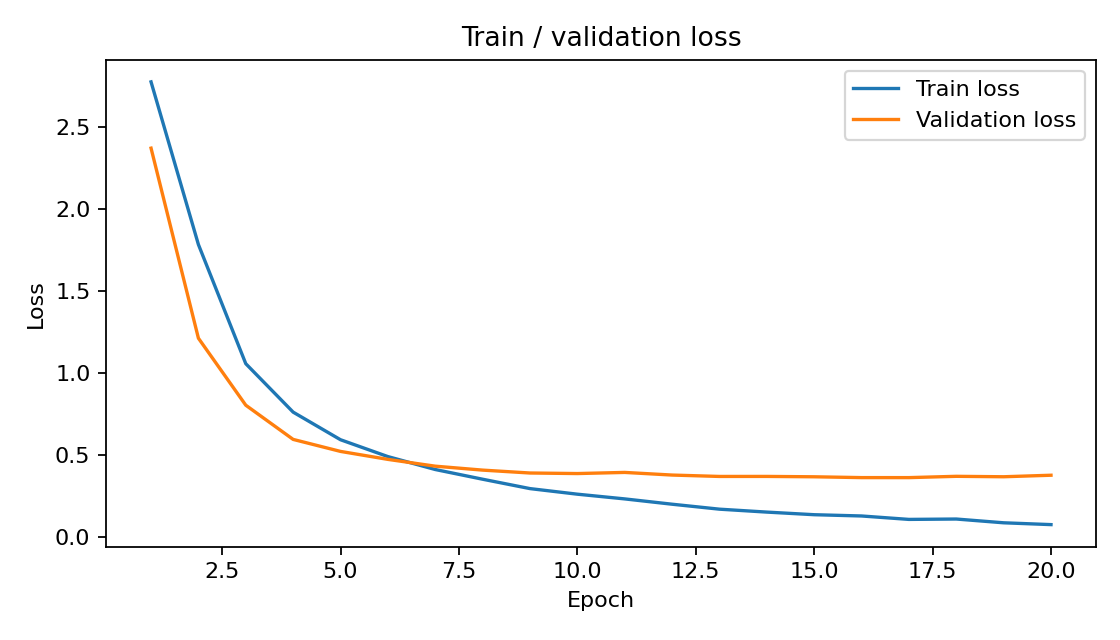

**Feature extraction và fine-tuning**

,Cấu hình,Tham số,Giây/epoch,Accuracy,Precision macro,Recall macro,F1 macro
5,ResNet50 · feature extraction,23551061,105.165222,0.746932,0.759094,0.755449,0.752839
6,ResNet50 · fine-tuning,23551061,115.291088,0.851092,0.850415,0.855980,0.851041


Comparison: /kaggle/working/outputs/bai4/comparison.csv
Chênh lệch macro-F1 (ResNet50 · fine-tuning − ResNet50 · feature extraction): +0.0982


**Transfer learning và huấn luyện từ đầu**

,Cấu hình,Tham số,Giây/epoch,Accuracy,Precision macro,Recall macro,F1 macro
3,ResNet-18 · có augmentation,11187285,88.147139,0.473661,0.492710,0.483473,0.471213
6,ResNet50 · fine-tuning,23551061,115.291088,0.851092,0.850415,0.855980,0.851041


Comparison: /kaggle/working/outputs/bai4/comparison_transfer.csv
Chênh lệch macro-F1 (ResNet50 · fine-tuning − ResNet-18 · có augmentation): +0.3798


In [8]:
run('resnet50_features')
run('resnet50_finetune')
frame = results_frame(results)
show_pair(frame, ['resnet50_features', 'resnet50_finetune'], 'Feature extraction và fine-tuning',
          output_path=OUTPUT_ROOT/'bai4'/'comparison.csv')
show_pair(frame, ['resnet18_aug', 'resnet50_finetune'], 'Transfer learning và huấn luyện từ đầu',
          output_path=OUTPUT_ROOT/'bai4'/'comparison_transfer.csv')


Fine-tuning ResNet50 đạt macro-F1 85,10%, cao hơn feature extraction 75,28% khoảng 9,82 điểm phần trăm. Cập nhật toàn bộ mạng giúp các đặc trưng pretrained thích nghi tốt hơn với VinaFood21; mô hình tốt nhất được chọn tại epoch 17 theo validation macro-F1.

So với ResNet18 có augmentation được huấn luyện từ đầu, macro-F1 tăng 37,98 điểm phần trăm. Cho thấy hiệu quả của Transfer Learning trong bài toán hiện tại.

In [11]:
from IPython.display import display, Markdown
from src.report import notebook_summary

display(Markdown("### Bảng tổng hợp kết quả"))

display(
    notebook_summary(results).style.format({
        "Tham số": "{:,.0f}",
        "Giây/epoch": "{:.2f}",
        "Accuracy": "{:.2%}",
        "macro-F1": "{:.2%}",
    })
)


### Bảng tổng hợp kết quả

,Mô hình,Resize,Tham số,Giây/epoch,Accuracy,macro-F1
0,LeNet · AvgPool,64×64,"339,421",113.84,26.74%,24.79%
1,LeNet · MaxPool,64×64,"339,421",81.06,29.56%,28.79%
2,GoogLeNet rút gọn,64×64,"78,221",81.21,39.00%,37.57%
3,ResNet-18 · có augmentation,96×96,"11,187,285",88.15,47.37%,47.12%
4,ResNet-18 · không augmentation,96×96,"11,187,285",83.81,40.11%,38.14%
5,ResNet50 · feature extraction,224×224,"23,551,061",105.17,74.69%,75.28%
6,ResNet50 · fine-tuning,224×224,"23,551,061",115.29,85.11%,85.10%
